# DPGAN effective-epsilon audit: threshold, orientation, TP/FP per epsilon

Re-computation from saved raw attack scores. 

For each epsilon, for each of the 5 attacks, use TAPAS's `EffectiveEpsilonReport` to 
- select threshold and orientation on validation slice
- count TP/FP on test slice
- compute eps_low, eps_high at 90, 95, 99 Clopper-Pearson CI
- check against saved per_attack eff_eps CSVs. 

num_train/num_test = 1000/2500

### Cell 1: setup and file locations

In [1]:
from pathlib import Path
from types import SimpleNamespace
import warnings

import numpy as np
import pandas as pd
from tapas.report import EffectiveEpsilonReport

warnings.filterwarnings("ignore")
pd.set_option("display.width", 250, "display.max_columns", 60, "display.float_format", lambda x: f"{x:.4f}")

# benchmark_tapas/ = nearest ancestor holding config.py (same trick as the audit scripts)
HERE = Path.cwd().resolve()
BENCH = next(p for p in [HERE, *HERE.parents] if (p / "config.py").exists())
RES = BENCH / "results"

# epsilon -> (raw scores CSV, per-attack effeps CSV), relative to RES
SOURCES = {
    0.1:   ("eps_sweep/dpgan/raw_scores_dpgan_eps0.1.csv",
            "eps_sweep/dpgan/eps0.1/effeps_dpgan_eps0.1.csv"),
    0.999: ("extras/dpgan_spike_diagnosis/privacy/raw_scores_dpgan_eps0.999.csv",
            "extras/dpgan_spike_diagnosis/privacy/eps0.999/effeps_dpgan_eps0.999.csv"),
    1.0:   ("sample_size_sweep/raw_scores_dpgan_1000_2500.csv",
            "sample_size_sweep/dpgan/1000_2500/effeps_dpgan_1000_2500.csv"),
    1.001: ("extras/dpgan_spike_diagnosis/privacy/raw_scores_dpgan_eps1.001.csv",
            "extras/dpgan_spike_diagnosis/privacy/eps1.001/effeps_dpgan_eps1.001.csv"),
    10.0:  ("eps_sweep/dpgan/raw_scores_dpgan_eps10.csv",
            "eps_sweep/dpgan/eps10/effeps_dpgan_eps10.csv"),
    100.0: ("eps_sweep/dpgan/raw_scores_dpgan_eps100.csv",
            "eps_sweep/dpgan/eps100/effeps_dpgan_eps100.csv"),
}
CONF = (0.9, 0.95, 0.99)
print("benchmark_tapas:", BENCH)
for eps, (raw, eff) in SOURCES.items():
    assert (RES / raw).exists() and (RES / eff).exists(), (eps, raw, eff)
    print(f"eps={eps:<6} raw={raw}\n{'':11}effeps={eff}")

benchmark_tapas: /Users/PengOlivia/Desktop/Uni/USYD VRI/priv-sdg/benchmark_tapas
eps=0.1    raw=eps_sweep/dpgan/raw_scores_dpgan_eps0.1.csv
           effeps=eps_sweep/dpgan/eps0.1/effeps_dpgan_eps0.1.csv
eps=0.999  raw=extras/dpgan_spike_diagnosis/privacy/raw_scores_dpgan_eps0.999.csv
           effeps=extras/dpgan_spike_diagnosis/privacy/eps0.999/effeps_dpgan_eps0.999.csv
eps=1.0    raw=sample_size_sweep/raw_scores_dpgan_1000_2500.csv
           effeps=sample_size_sweep/dpgan/1000_2500/effeps_dpgan_1000_2500.csv
eps=1.001  raw=extras/dpgan_spike_diagnosis/privacy/raw_scores_dpgan_eps1.001.csv
           effeps=extras/dpgan_spike_diagnosis/privacy/eps1.001/effeps_dpgan_eps1.001.csv
eps=10.0   raw=eps_sweep/dpgan/raw_scores_dpgan_eps10.csv
           effeps=eps_sweep/dpgan/eps10/effeps_dpgan_eps10.csv
eps=100.0  raw=eps_sweep/dpgan/raw_scores_dpgan_eps100.csv
           effeps=eps_sweep/dpgan/eps100/effeps_dpgan_eps100.csv


### Cell 2: load saved files
**Sources:** raw-score CSVs, per-attack eff_eps CSVs
- raw: `attack, ground_truth, raw_score`
- effeps: `attack, eps_low_90/95/99, eps_high_90/95/99`

In [2]:
def short(label: str) -> str:
    """'ClosestDistance(L_2, accuracy)' -> 'ClosestDistance' (names differ only in the suffix)."""
    return label.split("(")[0]

raw, saved = {}, {}
for eps, (rp, ep) in SOURCES.items():
    r = pd.read_csv(RES / rp)
    s = pd.read_csv(RES / ep)
    r["a"], s["a"] = r["attack"].map(short), s["attack"].map(short)
    raw[eps], saved[eps] = r, s
    print(f"eps={eps:<6} raw rows={len(r):<6} attacks={r['a'].nunique()}  effeps rows={len(s)}")

eps=0.1    raw rows=12500  attacks=5  effeps rows=5
eps=0.999  raw rows=12500  attacks=5  effeps rows=5
eps=1.0    raw rows=12500  attacks=5  effeps rows=5
eps=1.001  raw rows=12500  attacks=5  effeps rows=5
eps=10.0   raw rows=12500  attacks=5  effeps rows=5
eps=100.0  raw rows=12500  attacks=5  effeps rows=5


### Cell 3: recompute with TAPAS `EffectiveEpsilonReport`
**Sources:** 
- `raw` (raw-score CSVs from Cell 1). 
- Per attack, rows are taken in file order, as `summary.scores/labels` were.

Recomputation:
- `validation_split = min(0.5, max(0.1, 15 / n))` (same as `common.run_attack`); validation = `[:int(split*n)]`, test = the rest.
- `(threshold = tau, orientation = inverse true/false)` come from `EffectiveEpsilonReport._select_attack()` on the validation slice.
- Normal rule: positive class = label True, counted when `score >= tau`. Inverse rule: positive class = label False, counted when `score <= tau`.
- eps_low/eps_high come from the report's own `_estimate_effective_epsilon` on the test slice.

In [3]:
def audit_one(scores, labels):
    n = len(scores)
    split = min(0.5, max(0.1, 15 / n))
    report = EffectiveEpsilonReport([SimpleNamespace(scores=scores, labels=labels)],
                                    validation_split=split, confidence_levels=CONF)
    ''' Tie-break (TAPAS 1.0.0 report.py::_select_attack_cp): 
    (threshold, orientation) with highest validation eps_low_90 
    - Tries tau ascending, normal before inverse orientation
    - Must be strictly greater validation eps_low_90 to replace the best 
    '''
    sel = report._select_attack()
    k = int(split * n)
    out = dict(n=n, n_val=k, n_test=n - k, split=split)
    if sel is None:
        return {**out, "tau": np.nan, "inverse": None, "rule": "none selected",
                "P": 0, "N": 0, "TP": 0, "FP": 0, **{f"{b}_{c}": np.nan for b in ("eps_low", "eps_high") for c in (90, 95, 99)}}
    _, tau, inverse = sel
    ts, tl = scores[k:], labels[k:]
    pos_label = not inverse
    hit = (lambda x: x <= tau) if inverse else (lambda x: x >= tau)
    P, N = int((tl == pos_label).sum()), int((tl != pos_label).sum())
    TP = int(hit(ts[tl == pos_label]).sum())
    FP = int(hit(ts[tl != pos_label]).sum())
    rule = ("inverse: score <= tau, label False = positive" if inverse
            else "normal: score >= tau, label True = positive")
    out.update(tau=float(tau), inverse=bool(inverse), rule=rule, P=P, N=N, TP=TP, FP=FP)
    for c in CONF:
        lo, hi = report._estimate_effective_epsilon(ts, tl, tau, c, inverse)
        out[f"eps_low_{round(c*100)}"], out[f"eps_high_{round(c*100)}"] = lo, hi
    return out

rows = []
for eps, r in raw.items():
    order = list(saved[eps]["a"])               # saved-file attack order (used for tie-breaking, like idxmax)
    for att in order:
        g = r[r["a"] == att]
        res = audit_one(g["raw_score"].to_numpy(float), g["ground_truth"].to_numpy().astype(bool))
        rows.append(dict(epsilon=eps, attack=att, **res))
R = pd.DataFrame(rows)
R["TP/P"] = R.TP.astype(str) + "/" + R.P.astype(str)
R["FP/N"] = R.FP.astype(str) + "/" + R.N.astype(str)
print(f"{len(R)} rows recomputed ({R.epsilon.nunique()} epsilons x {R.attack.nunique()} attacks)")

30 rows recomputed (6 epsilons x 5 attacks)


### Cell 4: summary table, worst-case attack per epsilon
**Sources:** recomputed table `R` (from the raw-score CSVs in Cell 1); attack order for ties follows the saved effeps CSV order.

- Worst case = highest recomputed `eps_low_95` (`idxmax`, as the repo's aggregation does). 
- `n_tied` is how many attacks share that maximum (all five tie at 0 when no attack certifies any epsilon).

In [4]:
COLS = ["epsilon", "attack", "tau", "rule", "TP/P", "FP/N",
        "eps_low_90", "eps_high_90", "eps_low_95", "eps_high_95", "eps_low_99", "eps_high_99"]
worst = []
for eps, g in R.groupby("epsilon", sort=False):
    # Tie-break (manual, mirrors the repo's idxmax): ties on eps_low_95 go to the first attack in the saved effeps file order. 
    w = g.loc[g["eps_low_95"].idxmax()].copy()
    w["n_tied"] = int((g["eps_low_95"] == g["eps_low_95"].max()).sum())
    worst.append(w)
W = pd.DataFrame(worst)
W[COLS + ["n_tied"]].reset_index(drop=True)

,epsilon,attack,tau,rule,TP/P,FP/N,eps_low_90,eps_high_90,eps_low_95,eps_high_95,eps_low_99,eps_high_99,n_tied
0,0.1000,Groundhog,0.5700,"normal: score >= tau, label True = positive",202/1125,179/1125,0.0000,0.3857,0.0000,0.4231,0.0000,0.4985,5
1,0.9990,Groundhog,0.3400,"inverse: score <= tau, label False = positive",240/1125,11/1125,2.3875,3.8868,2.3032,4.0091,2.1384,4.2651,1
2,1.0000,Groundhog,0.6300,"normal: score >= tau, label True = positive",313/1125,33/1125,1.8179,2.7122,1.7613,2.7802,1.6493,2.9195,1
3,1.0010,Groundhog,0.6200,"normal: score >= tau, label True = positive",378/1125,32/1125,2.0446,2.9261,1.9893,2.9935,1.8799,3.1317,1
4,10.0000,Groundhog,0.2400,"normal: score >= tau, label True = positive",1125/1125,1122/1125,0.0000,0.0078,0.0000,0.0087,0.0000,0.0106,5
5,100.0000,Groundhog,0.3000,"normal: score >= tau, label True = positive",1122/1125,1121/1125,0.0000,0.0086,0.0000,0.0096,0.0000,0.0118,5


### Cell 5: one table per epsilon (all five attacks)
**Sources:** recomputed table `R` (raw-score CSVs from Cell 1). Same columns as the summary table; `P` and `N` are the test-slice class sizes for the chosen orientation.

In [5]:
from IPython.display import display, Markdown
for eps, g in R.groupby("epsilon", sort=False):
    src = SOURCES[eps][0]
    display(Markdown(f"#### epsilon = {eps}   (source: `results/{src}`; test slice n = {g.n_test.iloc[0]}, validation n = {g.n_val.iloc[0]}, split = {g.split.iloc[0]:.3f})"))
    display(g[COLS].reset_index(drop=True))

#### epsilon = 0.1   (source: `results/eps_sweep/dpgan/raw_scores_dpgan_eps0.1.csv`; test slice n = 2250, validation n = 250, split = 0.100)

,epsilon,attack,tau,rule,TP/P,FP/N,eps_low_90,eps_high_90,eps_low_95,eps_high_95,eps_low_99,eps_high_99
0,0.1000,Groundhog,0.5700,"normal: score >= tau, label True = positive",202/1125,179/1125,0.0000,0.3857,0.0000,0.4231,0.0000,0.4985
1,0.1000,ShadowModelling,0.1800,"normal: score >= tau, label True = positive",1123/1125,1125/1125,0.0000,0.0031,0.0000,0.0037,0.0000,0.0053
2,0.1000,LocalNeighbourhood,0.0000,"normal: score >= tau, label True = positive",1125/1125,1125/1125,0.0000,0.0033,0.0000,0.0039,0.0000,0.0053
3,0.1000,ProbabilityEstimation,-86.4915,"normal: score >= tau, label True = positive",1121/1125,1121/1125,0.0000,0.0081,0.0000,0.0093,0.0000,0.0116
4,0.1000,ClosestDistance,-2.1395,"normal: score >= tau, label True = positive",1124/1125,1125/1125,0.0000,0.0033,0.0000,0.0039,0.0000,0.0053


#### epsilon = 0.999   (source: `results/extras/dpgan_spike_diagnosis/privacy/raw_scores_dpgan_eps0.999.csv`; test slice n = 2250, validation n = 250, split = 0.100)

,epsilon,attack,tau,rule,TP/P,FP/N,eps_low_90,eps_high_90,eps_low_95,eps_high_95,eps_low_99,eps_high_99
0,0.9990,Groundhog,0.3400,"inverse: score <= tau, label False = positive",240/1125,11/1125,2.3875,3.8868,2.3032,4.0091,2.1384,4.2651
1,0.9990,ShadowModelling,0.2700,"inverse: score <= tau, label False = positive",57/1125,15/1125,0.5669,2.1643,0.4673,2.2853,0.2692,2.5347
2,0.9990,LocalNeighbourhood,0.0000,"normal: score >= tau, label True = positive",1125/1125,1125/1125,0.0000,0.0033,0.0000,0.0039,0.0000,0.0053
3,0.9990,ProbabilityEstimation,-89.2327,"normal: score >= tau, label True = positive",1124/1125,1123/1125,0.0000,0.0064,0.0000,0.0072,0.0000,0.0090
4,0.9990,ClosestDistance,-3.2344,"normal: score >= tau, label True = positive",1125/1125,1125/1125,0.0000,0.0033,0.0000,0.0039,0.0000,0.0053


#### epsilon = 1.0   (source: `results/sample_size_sweep/raw_scores_dpgan_1000_2500.csv`; test slice n = 2250, validation n = 250, split = 0.100)

...

,epsilon,attack,tau,rule,TP/P,FP/N,eps_low_90,eps_high_90,eps_low_95,eps_high_95,eps_low_99,eps_high_99
0,1.0010,Groundhog,0.6200,"normal: score >= tau, label True = positive",378/1125,32/1125,2.0446,2.9261,1.9893,2.9935,1.8799,3.1317
1,1.0010,ShadowModelling,0.2800,"inverse: score <= tau, label False = positive",60/1125,22/1125,0.3292,1.7121,0.2396,1.8141,0.0606,2.0227
2,1.0010,LocalNeighbourhood,0.0000,"normal: score >= tau, label True = positive",1125/1125,1125/1125,0.0000,0.0033,0.0000,0.0039,0.0000,0.0053
3,1.0010,ProbabilityEstimation,-89.2290,"normal: score >= tau, label True = positive",1124/1125,1123/1125,0.0000,0.0064,0.0000,0.0072,0.0000,0.0090
4,1.0010,ClosestDistance,-3.2273,"normal: score >= tau, label True = positive",1125/1125,1125/1125,0.0000,0.0033,0.0000,0.0039,0.0000,0.0053


#### epsilon = 10.0   (source: `results/eps_sweep/dpgan/raw_scores_dpgan_eps10.csv`; test slice n = 2250, validation n = 250, split = 0.100)

,epsilon,attack,tau,rule,TP/P,FP/N,eps_low_90,eps_high_90,eps_low_95,eps_high_95,eps_low_99,eps_high_99
0,10.0000,Groundhog,0.2400,"normal: score >= tau, label True = positive",1125/1125,1122/1125,0.0000,0.0078,0.0000,0.0087,0.0000,0.0106
1,10.0000,ShadowModelling,0.4900,"inverse: score <= tau, label False = positive",556/1125,537/1125,0.0000,0.1569,0.0000,0.1742,0.0000,0.2090
2,10.0000,LocalNeighbourhood,0.0000,"normal: score >= tau, label True = positive",1125/1125,1125/1125,0.0000,0.0033,0.0000,0.0039,0.0000,0.0053
3,10.0000,ProbabilityEstimation,-90.1666,"normal: score >= tau, label True = positive",1123/1125,1123/1125,0.0000,0.0062,0.0000,0.0071,0.0000,0.0089
4,10.0000,ClosestDistance,-3.5434,"normal: score >= tau, label True = positive",1119/1125,1111/1125,0.0000,0.0190,0.0000,0.0207,0.0000,0.0240


#### epsilon = 100.0   (source: `results/eps_sweep/dpgan/raw_scores_dpgan_eps100.csv`; test slice n = 2250, validation n = 250, split = 0.100)

,epsilon,attack,tau,rule,TP/P,FP/N,eps_low_90,eps_high_90,eps_low_95,eps_high_95,eps_low_99,eps_high_99
0,100.0000,Groundhog,0.3000,"normal: score >= tau, label True = positive",1122/1125,1121/1125,0.0000,0.0086,0.0000,0.0096,0.0000,0.0118
1,100.0000,ShadowModelling,0.2600,"normal: score >= tau, label True = positive",1121/1125,1115/1125,0.0000,0.0155,0.0000,0.0168,0.0000,0.0197
2,100.0000,LocalNeighbourhood,0.0000,"normal: score >= tau, label True = positive",1125/1125,1125/1125,0.0000,0.0033,0.0000,0.0039,0.0000,0.0053
3,100.0000,ProbabilityEstimation,-90.2266,"normal: score >= tau, label True = positive",1118/1125,1119/1125,0.0000,0.0091,0.0000,0.0105,0.0000,0.0133
4,100.0000,ClosestDistance,-3.8196,"normal: score >= tau, label True = positive",1125/1125,1125/1125,0.0000,0.0033,0.0000,0.0039,0.0000,0.0053


### Cell 6: check recomputed vs saved
**Sources:** recomputed `R`, and the saved per-attack effeps CSVs listed in Cell 1
(`eps_sweep/dpgan/eps0.1/…`, `extras/dpgan_spike_diagnosis/privacy/eps0.999/…`, `sample_size_sweep/dpgan/1000_2500/…`,
`extras/dpgan_spike_diagnosis/privacy/eps1.001/…`, `eps_sweep/dpgan/eps10/…`, `eps_sweep/dpgan/eps100/…`).
Columns compared: `eps_low_90/95/99` and `eps_high_90/95/99`, tolerance 1e-9. Infinite values must match exactly. The `effective_epsilon_<attack>.csv` files are not used.

In [6]:
TOL = 1e-9
BOUND_COLS = [f"{b}_{c}" for b in ("eps_low", "eps_high") for c in (90, 95, 99)]

def same(a, b):
    if np.isinf(a) or np.isinf(b):
        return a == b
    return bool(abs(a - b) <= TOL)

checks = []
for _, row in R.iterrows():
    s = saved[row.epsilon]
    s = s[s["a"] == row.attack]
    assert len(s) == 1, (row.epsilon, row.attack)
    s = s.iloc[0]
    ok_cols = {c: same(float(row[c]), float(s[c])) for c in BOUND_COLS}
    checks.append(dict(epsilon=row.epsilon, attack=row.attack,
                       result="PASS" if all(ok_cols.values()) else "FAIL",
                       max_abs_diff=max(abs(float(row[c]) - float(s[c])) if not (np.isinf(row[c]) or np.isinf(s[c])) else 0.0
                                        for c in BOUND_COLS),
                       failing=[c for c, v in ok_cols.items() if not v]))
CH = pd.DataFrame(checks)
for _, c in CH.iterrows():
    print(f"{c.result}  eps={c.epsilon:<6} {c.attack:<22} max|diff|={c.max_abs_diff:.2e}  {c.failing if c.failing else ''}")
n_pass = int((CH.result == "PASS").sum())
print(f"\n{n_pass}/{len(CH)} rows PASS")
assert n_pass == len(CH), "recomputed eps_low/eps_high differ from the saved per-attack effeps CSVs"

PASS  eps=0.1    Groundhog              max|diff|=3.33e-16  
PASS  eps=0.1    ShadowModelling        max|diff|=8.85e-17  
PASS  eps=0.1    LocalNeighbourhood     max|diff|=5.64e-17  
PASS  eps=0.1    ProbabilityEstimation  max|diff|=9.37e-17  
PASS  eps=0.1    ClosestDistance        max|diff|=9.63e-17  
PASS  eps=0.999  Groundhog              max|diff|=8.88e-16  
PASS  eps=0.999  ShadowModelling        max|diff|=4.44e-16  
PASS  eps=0.999  LocalNeighbourhood     max|diff|=5.64e-17  
PASS  eps=0.999  ProbabilityEstimation  max|diff|=8.85e-17  
PASS  eps=0.999  ClosestDistance        max|diff|=5.64e-17  
PASS  eps=1.0    Groundhog              max|diff|=8.88e-16  
PASS  eps=1.0    ShadowModelling        max|diff|=1.78e-15  
PASS  eps=1.0    LocalNeighbourhood     max|diff|=5.64e-17  
PASS  eps=1.0    ProbabilityEstimation  max|diff|=9.71e-17  
PASS  eps=1.0    ClosestDistance        max|diff|=5.29e-17  
PASS  eps=1.001  Groundhog              max|diff|=8.88e-16  
PASS  eps=1.001  ShadowM

## Part 2: per-run audit (tagged ε = 1 runs, ε = 0.5 / 2 / 5, and context runs)

Several runs now share an epsilon (five at ε = 1.0), so this part is keyed by **run label**, not by epsilon.
It reuses `audit_one` from Cell 3 unchanged, and the same tie-breaking as Cells 4 and 5. Nothing is written to disk.

- **Goal 1** (all ε = 1.0): `eps1` (baseline), `eps1_seedbase10000`, `eps1_tseed44`, `eps1_bg44`
- **Goal 2** (baseline setup): `eps0.5`, `eps2`, `eps5`
- **Context**: `eps0.1`, `eps10`, `eps100`, `eps0.999`, `eps1.001`, and the old ε = 1.0 audit from the counts sweep (`eps1_countsweep`)

### Cell 7: runs and file locations
**Sources:** `results/eps_sweep/dpgan/`, `results/extras/dpgan_spike_diagnosis/privacy/`, `results/sample_size_sweep/`.
Each run needs a raw-score CSV and one `effeps_dpgan_*.csv`; `meta.json` and the five `effective_epsilon_*.csv` are listed too. Missing files are reported, not guessed; a run without raw scores or effeps is dropped from the tables.

In [7]:
# run label -> (group, formal epsilon, raw-score CSV, results folder), relative to RES
RUNS = {
    "eps0.1":             ("context", 0.1,   "eps_sweep/dpgan/raw_scores_dpgan_eps0.1.csv",   "eps_sweep/dpgan/eps0.1"),
    "eps0.5":             ("goal 2",  0.5,   "eps_sweep/dpgan/raw_scores_dpgan_eps0.5.csv",   "eps_sweep/dpgan/eps0.5"),
    "eps0.999":           ("context", 0.999, "extras/dpgan_spike_diagnosis/privacy/raw_scores_dpgan_eps0.999.csv",
                                             "extras/dpgan_spike_diagnosis/privacy/eps0.999"),
    "eps1_countsweep":    ("context", 1.0,   "sample_size_sweep/raw_scores_dpgan_1000_2500.csv", "sample_size_sweep/dpgan/1000_2500"),
    "eps1":               ("goal 1",  1.0,   "eps_sweep/dpgan/raw_scores_dpgan_eps1.csv",     "eps_sweep/dpgan/eps1"),
    "eps1_seedbase10000": ("goal 1",  1.0,   "eps_sweep/dpgan/raw_scores_dpgan_eps1_seedbase10000.csv", "eps_sweep/dpgan/eps1_seedbase10000"),
    "eps1_tseed44":       ("goal 1",  1.0,   "eps_sweep/dpgan/raw_scores_dpgan_eps1_tseed44.csv",       "eps_sweep/dpgan/eps1_tseed44"),
    "eps1_bg44":          ("goal 1",  1.0,   "eps_sweep/dpgan/raw_scores_dpgan_eps1_bg44.csv",          "eps_sweep/dpgan/eps1_bg44"),
    "eps1.001":           ("context", 1.001, "extras/dpgan_spike_diagnosis/privacy/raw_scores_dpgan_eps1.001.csv",
                                             "extras/dpgan_spike_diagnosis/privacy/eps1.001"),
    "eps2":               ("goal 2",  2.0,   "eps_sweep/dpgan/raw_scores_dpgan_eps2.csv",     "eps_sweep/dpgan/eps2"),
    "eps5":               ("goal 2",  5.0,   "eps_sweep/dpgan/raw_scores_dpgan_eps5.csv",     "eps_sweep/dpgan/eps5"),
    "eps10":              ("context", 10.0,  "eps_sweep/dpgan/raw_scores_dpgan_eps10.csv",    "eps_sweep/dpgan/eps10"),
    "eps100":             ("context", 100.0, "eps_sweep/dpgan/raw_scores_dpgan_eps100.csv",   "eps_sweep/dpgan/eps100"),
}

inventory, LOADED, MISSING = [], [], {}
for label, (group, eps, raw_rel, folder) in RUNS.items():
    d = RES / folder
    eff = sorted(d.glob("effeps_dpgan_*.csv"))
    per_attack = sorted(d.glob("effective_epsilon_*.csv"))
    missing = []
    if not (RES / raw_rel).exists():
        missing.append("raw scores")
    if len(eff) != 1:
        missing.append(f"effeps CSV (found {len(eff)})")
    if not (d / "meta.json").exists():
        missing.append("meta.json")
    if len(per_attack) != 5:
        missing.append(f"effective_epsilon_*.csv (found {len(per_attack)}/5)")
    usable = (RES / raw_rel).exists() and len(eff) == 1
    if usable:
        LOADED.append(label)
    if missing:
        MISSING[label] = missing
    inventory.append(dict(run=label, group=group, epsilon=eps, usable=usable,
                          effeps=eff[0].relative_to(RES).as_posix() if len(eff) == 1 else None,
                          missing=", ".join(missing) or "-"))
INV = pd.DataFrame(inventory)
display(INV)
print(f"usable runs: {len(LOADED)}/{len(RUNS)}")
for label, m in MISSING.items():
    print(f"MISSING  {label}: {', '.join(m)}")

,run,group,epsilon,usable,effeps,missing
0,eps0.1,context,0.1000,True,eps_sweep/dpgan/eps0.1/effeps_dpgan_eps0.1.csv,-
1,eps0.5,goal 2,0.5000,True,eps_sweep/dpgan/eps0.5/effeps_dpgan_eps0.5.csv,-
2,eps0.999,context,0.9990,True,extras/dpgan_spike_diagnosis/privacy/eps0.999/...,-
3,eps1_countsweep,context,1.0000,True,sample_size_sweep/dpgan/1000_2500/effeps_dpgan...,meta.json
4,eps1,goal 1,1.0000,True,eps_sweep/dpgan/eps1/effeps_dpgan_eps1.csv,-
5,eps1_seedbase10000,goal 1,1.0000,True,eps_sweep/dpgan/eps1_seedbase10000/effeps_dpga...,-
6,eps1_tseed44,goal 1,1.0000,True,eps_sweep/dpgan/eps1_tseed44/effeps_dpgan_eps1...,-
7,eps1_bg44,goal 1,1.0000,True,eps_sweep/dpgan/eps1_bg44/effeps_dpgan_eps1_bg...,-
8,eps1.001,context,1.0010,True,extras/dpgan_spike_diagnosis/privacy/eps1.001/...,-
9,eps2,goal 2,2.0000,True,eps_sweep/dpgan/eps2/effeps_dpgan_eps2.csv,-


usable runs: 13/13
MISSING  eps1_countsweep: meta.json


### Cell 8: sigma per run
**Sources:** `results/eps_sweep/dpgan/noise_multipliers.csv` (`sigma_audit`) where it has the run's epsilon; otherwise Opacus 1.4.1
`get_noise_multiplier(target_epsilon=eps, target_delta=0.0025, sample_rate=0.5, epochs=50, accountant="prv")`, the audit world's
δ = 1/400, sample rate 1/len(loader) = 0.5 and 50 epochs. `sigma_source` says which was used. Opacus is also run for the epsilons the CSV covers, as a cross-check.

In [8]:
import opacus
from opacus.accountants.utils import get_noise_multiplier

NM = pd.read_csv(RES / "eps_sweep/dpgan/noise_multipliers.csv")
csv_sigma = dict(zip(NM.formal_epsilon.astype(float), NM.sigma_audit.astype(float)))
assert set(NM.delta_audit) == {0.0025} and set(NM.sample_rate_audit) == {0.5} and set(NM.accountant) == {"prv"}

computed = {eps: float(get_noise_multiplier(target_epsilon=eps, target_delta=0.0025, sample_rate=0.5,
                                            epochs=50, accountant="prv"))
            for eps in sorted({RUNS[l][1] for l in LOADED})}

sig = []
for label in LOADED:
    eps = RUNS[label][1]
    in_csv = eps in csv_sigma
    sig.append(dict(run=label, epsilon=eps,
                    sigma=csv_sigma[eps] if in_csv else computed[eps],
                    sigma_source="noise_multipliers.csv" if in_csv else f"opacus {opacus.__version__} get_noise_multiplier",
                    sigma_opacus=computed[eps],
                    csv_matches_opacus=(csv_sigma[eps] == computed[eps]) if in_csv else None))
SIG = pd.DataFrame(sig).set_index("run")
display(SIG)

,epsilon,sigma,sigma_source,sigma_opacus,csv_matches_opacus
run,,,,,
eps0.1,0.1000,80.0000,noise_multipliers.csv,80.0000,True
eps0.5,0.5000,20.9375,opacus 1.4.1 get_noise_multiplier,20.9375,None
eps0.999,0.9990,11.7188,opacus 1.4.1 get_noise_multiplier,11.7188,None
eps1_countsweep,1.0000,11.7188,noise_multipliers.csv,11.7188,True
eps1,1.0000,11.7188,noise_multipliers.csv,11.7188,True
eps1_seedbase10000,1.0000,11.7188,noise_multipliers.csv,11.7188,True
eps1_tseed44,1.0000,11.7188,noise_multipliers.csv,11.7188,True
eps1_bg44,1.0000,11.7188,noise_multipliers.csv,11.7188,True
eps1.001,1.0010,11.7188,opacus 1.4.1 get_noise_multiplier,11.7188,None


### Cell 9: load and recompute every run (all five attacks)
**Sources:** the raw-score CSV and the effeps CSV of each usable run from Cell 7. Same recomputation as Cell 3 (`audit_one`): rows in file order,
validation slice first, attack order taken from the saved effeps CSV.

In [9]:
raw2, saved2 = {}, {}
for label in LOADED:
    r = pd.read_csv(RES / RUNS[label][2])
    s = pd.read_csv(RES / INV.set_index("run").loc[label, "effeps"])
    r["a"], s["a"] = r["attack"].map(short), s["attack"].map(short)
    raw2[label], saved2[label] = r, s
    print(f"{label:<20} raw rows={len(r):<6} attacks={r['a'].nunique()}  effeps rows={len(s)}")

rows = []
for label in LOADED:
    r = raw2[label]
    for att in saved2[label]["a"]:
        g = r[r["a"] == att]
        res = audit_one(g["raw_score"].to_numpy(float), g["ground_truth"].to_numpy().astype(bool))
        rows.append(dict(run=label, group=RUNS[label][0], epsilon=RUNS[label][1],
                         sigma=SIG.loc[label, "sigma"], attack=att, **res))
R2 = pd.DataFrame(rows)
R2["TP/P"] = R2.TP.astype(str) + "/" + R2.P.astype(str)
R2["FP/N"] = R2.FP.astype(str) + "/" + R2.N.astype(str)
print(f"\n{len(R2)} rows recomputed ({R2.run.nunique()} runs x {R2.attack.nunique()} attacks)")

eps0.1               raw rows=12500  attacks=5  effeps rows=5
eps0.5               raw rows=12500  attacks=5  effeps rows=5
eps0.999             raw rows=12500  attacks=5  effeps rows=5
eps1_countsweep      raw rows=12500  attacks=5  effeps rows=5
eps1                 raw rows=12500  attacks=5  effeps rows=5
eps1_seedbase10000   raw rows=12500  attacks=5  effeps rows=5
eps1_tseed44         raw rows=12500  attacks=5  effeps rows=5
eps1_bg44            raw rows=12500  attacks=5  effeps rows=5
eps1.001             raw rows=12500  attacks=5  effeps rows=5
eps2                 raw rows=12500  attacks=5  effeps rows=5
eps5                 raw rows=12500  attacks=5  effeps rows=5
eps10                raw rows=12500  attacks=5  effeps rows=5
eps100               raw rows=12500  attacks=5  effeps rows=5



65 rows recomputed (13 runs x 5 attacks)


### Cell 10: master table, worst-case attack per run, sorted by sigma (descending)
**Sources:** recomputed `R2` (Cell 9) and sigma from Cell 8.

- Worst case = highest recomputed `eps_low_95` (`idxmax`, ties to the first attack in the saved effeps order, as in Cell 4); `n_tied` counts attacks sharing that maximum.
- Runs with equal sigma keep the order of `RUNS` (stable sort).

In [10]:
COLS2 = ["run", "epsilon", "sigma", "attack", "tau", "rule", "TP/P", "FP/N",
         "eps_low_90", "eps_low_95", "eps_low_99", "eps_high_90", "eps_high_95", "eps_high_99", "n_tied"]
worst2 = []
for label, g in R2.groupby("run", sort=False):
    w = g.loc[g["eps_low_95"].idxmax()].copy()
    w["n_tied"] = int((g["eps_low_95"] == g["eps_low_95"].max()).sum())
    worst2.append(w)
W2 = (pd.DataFrame(worst2)
        .assign(_order=lambda d: d.run.map({l: i for i, l in enumerate(RUNS)}))
        .sort_values(["sigma", "_order"], ascending=[False, True], kind="stable")
        .drop(columns="_order").reset_index(drop=True))
with pd.option_context("display.float_format", lambda x: f"{x:.4f}", "display.max_colwidth", 60):
    display(W2[COLS2])

,run,epsilon,sigma,attack,tau,rule,TP/P,FP/N,eps_low_90,eps_low_95,eps_low_99,eps_high_90,eps_high_95,eps_high_99,n_tied
0,eps0.1,0.1000,80.0000,Groundhog,0.5700,"normal: score >= tau, label True = positive",202/1125,179/1125,0.0000,0.0000,0.0000,0.3857,0.4231,0.4985,5
1,eps0.5,0.5000,20.9375,Groundhog,0.2600,"inverse: score <= tau, label False = positive",682/1125,3/1125,4.3071,4.1952,3.9821,7.0508,7.3232,7.9238,1
2,eps0.999,0.9990,11.7188,Groundhog,0.3400,"inverse: score <= tau, label False = positive",240/1125,11/1125,2.3875,2.3032,2.1384,3.8868,4.0091,4.2651,1
3,eps1_countsweep,1.0000,11.7188,Groundhog,0.6300,"normal: score >= tau, label True = positive",313/1125,33/1125,1.8179,1.7613,1.6493,2.7122,2.7802,2.9195,1
4,eps1,1.0000,11.7188,Groundhog,0.4100,"inverse: score <= tau, label False = positive",487/1125,69/1125,1.6571,1.6171,1.5375,2.2647,2.3098,2.4017,1
5,eps1_seedbase10000,1.0000,11.7188,Groundhog,0.6000,"normal: score >= tau, label True = positive",367/1125,14/1125,2.6654,2.5917,2.4472,3.9509,4.0544,4.2701,1
6,eps1_tseed44,1.0000,11.7188,Groundhog,0.3100,"inverse: score <= tau, label False = positive",622/1125,20/1125,2.9524,2.8917,2.7727,3.9788,4.0601,4.2285,1
7,eps1_bg44,1.0000,11.7188,Groundhog,0.6100,"normal: score >= tau, label True = positive",786/1125,32/1125,2.8218,2.7730,2.6769,3.6145,3.6758,3.8020,1
8,eps1.001,1.0010,11.7188,Groundhog,0.6200,"normal: score >= tau, label True = positive",378/1125,32/1125,2.0446,1.9893,1.8799,2.9261,2.9935,3.1317,1
9,eps2,2.0000,6.6992,Groundhog,0.3400,"inverse: score <= tau, label False = positive",158/1125,16/1125,1.6577,1.5777,1.4200,2.9903,3.0946,3.3104,1


### Cell 11: one table per run (all five attacks)
**Sources:** recomputed `R2` (Cell 9). Same columns as Cell 10 minus `n_tied`; runs in the master-table order. `P` and `N` are the test-slice class sizes for the chosen orientation.

In [11]:
for label in W2.run:
    g = R2[R2.run == label]
    display(Markdown(f"#### {label}   (ε = {RUNS[label][1]}, σ = {SIG.loc[label, 'sigma']:.6g}; source: `results/{RUNS[label][2]}`; "
                     f"test slice n = {g.n_test.iloc[0]}, validation n = {g.n_val.iloc[0]}, split = {g.split.iloc[0]:.3f})"))
    display(g[COLS2[:-1]].reset_index(drop=True))

#### eps0.1   (ε = 0.1, σ = 80; source: `results/eps_sweep/dpgan/raw_scores_dpgan_eps0.1.csv`; test slice n = 2250, validation n = 250, split = 0.100)

,run,epsilon,sigma,attack,tau,rule,TP/P,FP/N,eps_low_90,eps_low_95,eps_low_99,eps_high_90,eps_high_95,eps_high_99
0,eps0.1,0.1000,80.0000,Groundhog,0.5700,"normal: score >= tau, label True = positive",202/1125,179/1125,0.0000,0.0000,0.0000,0.3857,0.4231,0.4985
1,eps0.1,0.1000,80.0000,ShadowModelling,0.1800,"normal: score >= tau, label True = positive",1123/1125,1125/1125,0.0000,0.0000,0.0000,0.0031,0.0037,0.0053
2,eps0.1,0.1000,80.0000,LocalNeighbourhood,0.0000,"normal: score >= tau, label True = positive",1125/1125,1125/1125,0.0000,0.0000,0.0000,0.0033,0.0039,0.0053
3,eps0.1,0.1000,80.0000,ProbabilityEstimation,-86.4915,"normal: score >= tau, label True = positive",1121/1125,1121/1125,0.0000,0.0000,0.0000,0.0081,0.0093,0.0116
4,eps0.1,0.1000,80.0000,ClosestDistance,-2.1395,"normal: score >= tau, label True = positive",1124/1125,1125/1125,0.0000,0.0000,0.0000,0.0033,0.0039,0.0053


#### eps0.5   (ε = 0.5, σ = 20.9375; source: `results/eps_sweep/dpgan/raw_scores_dpgan_eps0.5.csv`; test slice n = 2250, validation n = 250, split = 0.100)

,run,epsilon,sigma,attack,tau,rule,TP/P,FP/N,eps_low_90,eps_low_95,eps_low_99,eps_high_90,eps_high_95,eps_high_99
0,eps0.5,0.5000,20.9375,Groundhog,0.2600,"inverse: score <= tau, label False = positive",682/1125,3/1125,4.3071,4.1952,3.9821,7.0508,7.3232,7.9238
1,eps0.5,0.5000,20.9375,ShadowModelling,0.2300,"normal: score >= tau, label True = positive",1116/1125,1117/1125,0.0000,0.0000,0.0000,0.0104,0.0119,0.0151
2,eps0.5,0.5000,20.9375,LocalNeighbourhood,0.0000,"normal: score >= tau, label True = positive",1125/1125,1125/1125,0.0000,0.0000,0.0000,0.0033,0.0039,0.0053
3,eps0.5,0.5000,20.9375,ProbabilityEstimation,-88.7798,"normal: score >= tau, label True = positive",1121/1125,1123/1125,0.0000,0.0000,0.0000,0.0055,0.0064,0.0085
4,eps0.5,0.5000,20.9375,ClosestDistance,-3.0026,"normal: score >= tau, label True = positive",1121/1125,1122/1125,0.0000,0.0000,0.0000,0.0068,0.0079,0.0101


#### eps0.999   (ε = 0.999, σ = 11.7188; source: `results/extras/dpgan_spike_diagnosis/privacy/raw_scores_dpgan_eps0.999.csv`; test slice n = 2250, validation n = 250, split = 0.100)

...

,run,epsilon,sigma,attack,tau,rule,TP/P,FP/N,eps_low_90,eps_low_95,eps_low_99,eps_high_90,eps_high_95,eps_high_99
0,eps5,5.0000,3.3057,Groundhog,0.5300,"normal: score >= tau, label True = positive",489/1125,369/1125,0.1292,0.1078,0.0647,0.4346,0.4563,0.5001
1,eps5,5.0000,3.3057,ShadowModelling,0.2700,"normal: score >= tau, label True = positive",1115/1125,1112/1125,0.0000,0.0000,0.0000,0.0156,0.0174,0.0210
2,eps5,5.0000,3.3057,LocalNeighbourhood,0.0000,"normal: score >= tau, label True = positive",1125/1125,1125/1125,0.0000,0.0000,0.0000,0.0033,0.0039,0.0053
3,eps5,5.0000,3.3057,ProbabilityEstimation,-90.1261,"normal: score >= tau, label True = positive",1122/1125,1123/1125,0.0000,0.0000,0.0000,0.0059,0.0068,0.0088
4,eps5,5.0000,3.3057,ClosestDistance,-3.6080,"normal: score >= tau, label True = positive",1124/1125,1125/1125,0.0000,0.0000,0.0000,0.0033,0.0039,0.0053


#### eps10   (ε = 10.0, σ = 2.01416; source: `results/eps_sweep/dpgan/raw_scores_dpgan_eps10.csv`; test slice n = 2250, validation n = 250, split = 0.100)

,run,epsilon,sigma,attack,tau,rule,TP/P,FP/N,eps_low_90,eps_low_95,eps_low_99,eps_high_90,eps_high_95,eps_high_99
0,eps10,10.0000,2.0142,Groundhog,0.2400,"normal: score >= tau, label True = positive",1125/1125,1122/1125,0.0000,0.0000,0.0000,0.0078,0.0087,0.0106
1,eps10,10.0000,2.0142,ShadowModelling,0.4900,"inverse: score <= tau, label False = positive",556/1125,537/1125,0.0000,0.0000,0.0000,0.1569,0.1742,0.2090
2,eps10,10.0000,2.0142,LocalNeighbourhood,0.0000,"normal: score >= tau, label True = positive",1125/1125,1125/1125,0.0000,0.0000,0.0000,0.0033,0.0039,0.0053
3,eps10,10.0000,2.0142,ProbabilityEstimation,-90.1666,"normal: score >= tau, label True = positive",1123/1125,1123/1125,0.0000,0.0000,0.0000,0.0062,0.0071,0.0089
4,eps10,10.0000,2.0142,ClosestDistance,-3.5434,"normal: score >= tau, label True = positive",1119/1125,1111/1125,0.0000,0.0000,0.0000,0.0190,0.0207,0.0240


#### eps100   (ε = 100.0, σ = 0.527306; source: `results/eps_sweep/dpgan/raw_scores_dpgan_eps100.csv`; test slice n = 2250, validation n = 250, split = 0.100)

,run,epsilon,sigma,attack,tau,rule,TP/P,FP/N,eps_low_90,eps_low_95,eps_low_99,eps_high_90,eps_high_95,eps_high_99
0,eps100,100.0000,0.5273,Groundhog,0.3000,"normal: score >= tau, label True = positive",1122/1125,1121/1125,0.0000,0.0000,0.0000,0.0086,0.0096,0.0118
1,eps100,100.0000,0.5273,ShadowModelling,0.2600,"normal: score >= tau, label True = positive",1121/1125,1115/1125,0.0000,0.0000,0.0000,0.0155,0.0168,0.0197
2,eps100,100.0000,0.5273,LocalNeighbourhood,0.0000,"normal: score >= tau, label True = positive",1125/1125,1125/1125,0.0000,0.0000,0.0000,0.0033,0.0039,0.0053
3,eps100,100.0000,0.5273,ProbabilityEstimation,-90.2266,"normal: score >= tau, label True = positive",1118/1125,1119/1125,0.0000,0.0000,0.0000,0.0091,0.0105,0.0133
4,eps100,100.0000,0.5273,ClosestDistance,-3.8196,"normal: score >= tau, label True = positive",1125/1125,1125/1125,0.0000,0.0000,0.0000,0.0033,0.0039,0.0053


### Cell 12: checks
**Sources:** recomputed `R2`, the saved effeps CSVs, the raw-score CSVs and each run's `meta.json`.

- Recomputed `eps_low/eps_high` at 90/95/99 vs the saved effeps CSV, tolerance 1e-9 (as Cell 6).
- Raw scores: 12,500 rows, 5 attacks, 2,500 per attack.
- `meta.json` (where present): `formal_epsilon` equals the run's epsilon, `num_train`/`num_test` = 1000/2500, and, where recorded, no degenerate pool and all distinct fractions = 1.0.

In [12]:
import json
checks2 = []
for _, row in R2.iterrows():
    s = saved2[row.run]
    s = s[s["a"] == row.attack]
    assert len(s) == 1, (row.run, row.attack)
    s = s.iloc[0]
    bad = [c for c in BOUND_COLS if not same(float(row[c]), float(s[c]))]
    diff = max(abs(float(row[c]) - float(s[c])) for c in BOUND_COLS
               if not (np.isinf(row[c]) or np.isinf(s[c])))
    checks2.append(dict(run=row.run, check=f"recompute vs saved: {row.attack}",
                        result="PASS" if not bad else "FAIL", detail=f"max|diff|={diff:.2e} {bad if bad else ''}"))

for label in LOADED:
    r = raw2[label]
    per = r.groupby("a").size()
    ok = len(r) == 12500 and len(per) == 5 and set(per) == {2500}
    checks2.append(dict(run=label, check="raw scores 12500 rows / 5 x 2500",
                        result="PASS" if ok else "FAIL", detail=f"rows={len(r)}, per attack={sorted(set(per))}"))
    mp = RES / RUNS[label][3] / "meta.json"
    if not mp.exists():
        checks2.append(dict(run=label, check="meta.json", result="NOT CHECKED", detail="meta.json missing"))
        continue
    m = json.loads(mp.read_text())
    problems = []
    if not np.isclose(float(m.get("formal_epsilon", np.nan)), RUNS[label][1]):
        problems.append(f"formal_epsilon={m.get('formal_epsilon')}")
    if (m.get("num_train"), m.get("num_test")) != (1000, 2500):
        problems.append(f"counts={m.get('num_train')}/{m.get('num_test')}")
    if m.get("degenerate_pool") is True:
        problems.append("degenerate_pool")
    fr = m.get("distinct_fractions") or {}
    if any(v != 1.0 for v in fr.values()):
        problems.append(f"distinct={fr}")
    checks2.append(dict(run=label, check="meta.json", result="FAIL" if problems else "PASS",
                        detail=", ".join(problems) or f"distinct fractions {'all 1.0' if fr else 'not recorded'}"))

CH2 = pd.DataFrame(checks2)
with pd.option_context("display.max_rows", 200, "display.max_colwidth", 80):
    display(CH2[CH2.result != "PASS"] if (CH2.result != "PASS").any() else CH2.head(0))
print(CH2.groupby("result").size().to_string())

,run,check,result,detail
72,eps1_countsweep,meta.json,NOT CHECKED,meta.json missing


result
NOT CHECKED     1
PASS           90


### Cell 13: worst-case eps_low_95 and eps_high_95 per run
**Sources:** master table `W2` (Cell 10). Left: against sigma (log x, descending). Right: against formal epsilon (log x).
Filled marker = `eps_low_95`, hollow marker = `eps_high_95`, joined by a line.

Runs that share an x value (within 0.1%) are **offset sideways for legibility**: the plot marks each such group with a shaded band,
a bracket with a tick at the true x, and a note giving the shared σ or ε. Plotted x positions inside a band are not real values; the true ones are in the Cell 10 table.

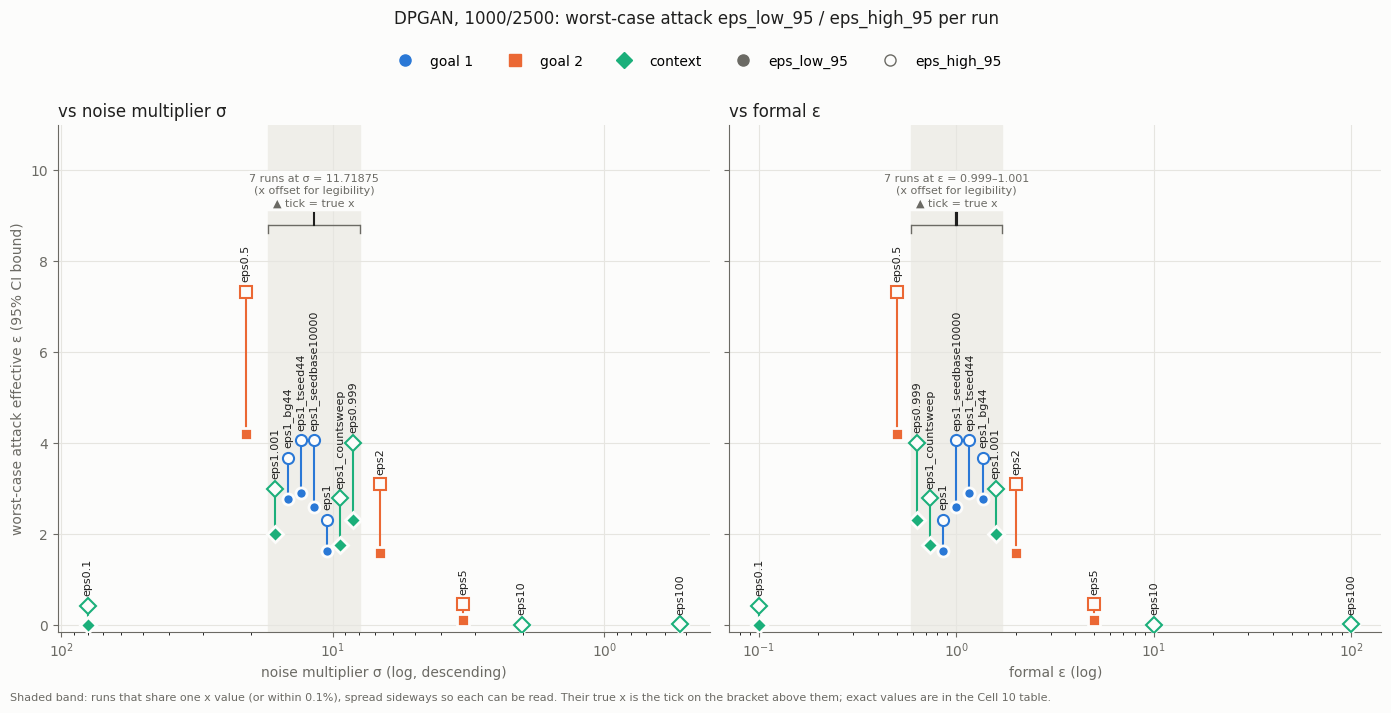

In [13]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

INK, MUTED, GRID, SURFACE, BAND = "#1f1f1e", "#6b6a64", "#e6e5e0", "#fcfcfb", "#efeee9"
GROUP_STYLE = {"goal 1": ("#2a78d6", "o"), "goal 2": ("#eb6834", "s"), "context": ("#1baf7a", "D")}

def dodge(x, tol=0.02, frac=0.022):
    """Spread points whose log10(x) lies within tol of each other, centred on the cluster. The step is a fixed
    fraction of the panel's decade span, so both panels get the same on-screen spacing.
    Returns (plotted x, clusters), each cluster = (true x values, plotted x values) for groups of 2 or more."""
    lx = np.log10(np.asarray(x, float))
    step = frac * (lx.max() - lx.min())
    order = np.argsort(lx, kind="stable")
    out, clusters, cluster = lx.copy(), [], [order[0]]
    def place(c):
        m = len(c)
        for i, j in enumerate(sorted(c, key=lambda j: W2.index[j])):
            out[j] = lx[c].mean() + (i - (m - 1) / 2) * step
        if m > 1:
            clusters.append((10 ** lx[c], 10 ** out[c]))
    for j in order[1:]:
        if lx[j] - lx[cluster[-1]] < tol:
            cluster.append(j)
        else:
            place(cluster); cluster = [j]
    place(cluster)
    return 10 ** out, clusters

def band_label(true_x, col):
    lo, hi = true_x.min(), true_x.max()
    if col == "sigma":
        val = f"σ = {lo:.7g}" if lo == hi else f"σ = {lo:.7g}–{hi:.7g}"
    else:
        val = f"ε = {lo:g}" if lo == hi else f"ε = {lo:g}–{hi:g}"
    return f"{len(true_x)} runs at {val}\n(x offset for legibility)"

fig, axes = plt.subplots(1, 2, figsize=(14, 6.4), sharey=True)
fig.patch.set_facecolor(SURFACE)
top = float(W2.eps_high_95.max())
for ax, col, xlabel in ((axes[0], "sigma", "noise multiplier σ (log, descending)"),
                        (axes[1], "epsilon", "formal ε (log)")):
    ax.set_facecolor(SURFACE)
    xs, clusters = dodge(W2[col])
    # Shared-x clusters: shaded band over the offset points, a bracket above the data with a tick at the
    # true x, and a note. The tick sits above the data so it never crosses a run's line or label.
    for true_x, plotted_x in clusters:
        pad = (plotted_x.max() / plotted_x.min()) ** (0.5 / (len(plotted_x) - 1))
        x0, x1 = plotted_x.min() / pad, plotted_x.max() * pad
        ax.axvspan(x0, x1, color=BAND, zorder=0)
        yb = top * 1.2
        ax.plot([x0, x1], [yb, yb], color=MUTED, lw=1, zorder=1, solid_capstyle="butt")
        for xe in (x0, x1):
            ax.plot([xe, xe], [yb, yb - top * 0.025], color=MUTED, lw=1, zorder=1)
        for tx in np.unique(true_x):
            ax.plot([tx, tx], [yb, yb + top * 0.035], color=INK, lw=1.5, zorder=1)
        ax.text(np.sqrt(x0 * x1), yb + top * 0.05, band_label(true_x, col) + "\n▲ tick = true x",
                ha="center", va="bottom", fontsize=8, color=MUTED, linespacing=1.3,
                bbox=dict(boxstyle="round,pad=0.25", fc=SURFACE, ec="none"), zorder=4)
    for x, (_, w) in zip(xs, W2.iterrows()):
        color, marker = GROUP_STYLE[w.group]
        ax.plot([x, x], [w.eps_low_95, w.eps_high_95], color=color, lw=1.5, zorder=2)
        ax.plot(x, w.eps_low_95, marker=marker, ms=8, color=color, mec=SURFACE, mew=2, ls="none", zorder=3)
        ax.plot(x, w.eps_high_95, marker=marker, ms=8, mfc=SURFACE, mec=color, mew=1.5, ls="none", zorder=3)
        ax.annotate(w.run, (x, w.eps_high_95), xytext=(0, 7), textcoords="offset points",
                    rotation=90, ha="center", va="bottom", fontsize=8, color=INK)
    ax.set_xscale("log")
    if col == "sigma":
        ax.invert_xaxis()
    ax.set_xlabel(xlabel, color=MUTED)
    ax.grid(True, which="major", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(MUTED)
    ax.tick_params(colors=MUTED)
axes[0].set_ylabel("worst-case attack effective ε (95% CI bound)", color=MUTED)
axes[0].set_ylim(-0.15, top * 1.5)
axes[0].set_title("vs noise multiplier σ", color=INK, loc="left")
axes[1].set_title("vs formal ε", color=INK, loc="left")

handles = [Line2D([], [], color=c, marker=m, ms=8, ls="none", label=g) for g, (c, m) in GROUP_STYLE.items()]
handles += [Line2D([], [], color=MUTED, marker="o", ms=8, ls="none", label="eps_low_95"),
            Line2D([], [], color=MUTED, marker="o", ms=8, mfc=SURFACE, ls="none", label="eps_high_95")]
fig.legend(handles=handles, loc="upper center", ncol=5, frameon=False, bbox_to_anchor=(0.5, 1.02))
fig.suptitle("DPGAN, 1000/2500: worst-case attack eps_low_95 / eps_high_95 per run", y=1.07, color=INK)
fig.text(0.01, -0.01, "Shaded band: runs that share one x value (or within 0.1%), spread sideways so each can be read. "
         "Their true x is the tick on the bracket above them; exact values are in the Cell 10 table.", fontsize=8, color=MUTED, ha="left")
plt.tight_layout()
plt.show()

## Part 3: seed-fix runs (ε = 0.1 / 0.5 / 1 / 2 / 5 / 10 / 100, tag `seedfix`)

The three runs made with `--seed-fix` (`SynthcityGenerator(seed_fix=True)`): every `enable_reproducible_results` call inside a fit and its `generate` uses that fit's seed. Same background, target pair, attack seed, counts (1000/2500) and `n_iter` as the earlier runs at the same ε.
Same recomputation as Parts 1 and 2: it reuses `audit_one` (Cell 3), `short` (Cell 2), `same` / `BOUND_COLS` (Cell 6) and `COLS2` (Cell 10) unchanged. Nothing is written to disk.

### Cell 14: runs, file locations and sigma
**Sources:** `results/eps_sweep/dpgan/eps{0.1,0.5,1,2,5,10,100}_seedfix/` (`effeps_dpgan_*.csv`, `meta.json`, the five `effective_epsilon_*.csv`), `raw_scores_dpgan_eps*_seedfix.csv`, `noise_multipliers.csv`.
Sigma as in Cell 8: `noise_multipliers.csv` (`sigma_audit`) where it has the run's ε, otherwise Opacus `get_noise_multiplier(target_delta=0.0025, sample_rate=0.5, epochs=50, accountant="prv")`; Opacus is also run for the ε the CSV covers, as a cross-check. Groups follow the old run at the same ε (Part 2).

In [14]:
# run label -> (group, formal epsilon, raw-score CSV, results folder, old run at the same epsilon), relative to RES
RUNS3 = {
    "eps0.1_seedfix": ("context", 0.1,   "eps_sweep/dpgan/raw_scores_dpgan_eps0.1_seedfix.csv", "eps_sweep/dpgan/eps0.1_seedfix", "eps0.1"),
    "eps0.5_seedfix": ("goal 2",  0.5,   "eps_sweep/dpgan/raw_scores_dpgan_eps0.5_seedfix.csv", "eps_sweep/dpgan/eps0.5_seedfix", "eps0.5"),
    "eps1_seedfix":   ("goal 1",  1.0,   "eps_sweep/dpgan/raw_scores_dpgan_eps1_seedfix.csv",   "eps_sweep/dpgan/eps1_seedfix",   "eps1"),
    "eps2_seedfix":   ("goal 2",  2.0,   "eps_sweep/dpgan/raw_scores_dpgan_eps2_seedfix.csv",   "eps_sweep/dpgan/eps2_seedfix",   "eps2"),
    "eps5_seedfix":   ("goal 2",  5.0,   "eps_sweep/dpgan/raw_scores_dpgan_eps5_seedfix.csv",   "eps_sweep/dpgan/eps5_seedfix",   "eps5"),
    "eps10_seedfix":  ("context", 10.0,  "eps_sweep/dpgan/raw_scores_dpgan_eps10_seedfix.csv",  "eps_sweep/dpgan/eps10_seedfix",  "eps10"),
    "eps100_seedfix": ("context", 100.0, "eps_sweep/dpgan/raw_scores_dpgan_eps100_seedfix.csv", "eps_sweep/dpgan/eps100_seedfix", "eps100"),
}
SEEDFIX_LOG = RES / "eps_sweep/dpgan/eps_sweep_privacy_log_seedfix.txt"

inventory3, LOADED3, MISSING3 = [], [], {}
for label, (group, eps, raw_rel, folder, old) in RUNS3.items():
    d = RES / folder
    eff = sorted(d.glob("effeps_dpgan_*.csv"))
    per_attack = sorted(d.glob("effective_epsilon_*.csv"))
    missing = []
    if not (RES / raw_rel).exists():
        missing.append("raw scores")
    if len(eff) != 1:
        missing.append(f"effeps CSV (found {len(eff)})")
    if not (d / "meta.json").exists():
        missing.append("meta.json")
    if len(per_attack) != 5:
        missing.append(f"effective_epsilon_*.csv (found {len(per_attack)}/5)")
    usable = (RES / raw_rel).exists() and len(eff) == 1
    if usable:
        LOADED3.append(label)
    if missing:
        MISSING3[label] = missing
    inventory3.append(dict(run=label, group=group, epsilon=eps, usable=usable,
                           effeps=eff[0].relative_to(RES).as_posix() if len(eff) == 1 else None,
                           missing=", ".join(missing) or "-"))
INV3 = pd.DataFrame(inventory3)
display(INV3)
print(f"usable runs: {len(LOADED3)}/{len(RUNS3)}")
for label, m in MISSING3.items():
    print(f"MISSING  {label}: {', '.join(m)}")

import opacus
from opacus.accountants.utils import get_noise_multiplier

NM3 = pd.read_csv(RES / "eps_sweep/dpgan/noise_multipliers.csv")
csv_sigma3 = dict(zip(NM3.formal_epsilon.astype(float), NM3.sigma_audit.astype(float)))
assert set(NM3.delta_audit) == {0.0025} and set(NM3.sample_rate_audit) == {0.5} and set(NM3.accountant) == {"prv"}
computed3 = {eps: float(get_noise_multiplier(target_epsilon=eps, target_delta=0.0025, sample_rate=0.5,
                                             epochs=50, accountant="prv"))
             for eps in sorted({RUNS3[l][1] for l in LOADED3})}
sig3 = []
for label in LOADED3:
    eps = RUNS3[label][1]
    in_csv = eps in csv_sigma3
    sig3.append(dict(run=label, epsilon=eps,
                     sigma=csv_sigma3[eps] if in_csv else computed3[eps],
                     sigma_source="noise_multipliers.csv" if in_csv else f"opacus {opacus.__version__} get_noise_multiplier",
                     sigma_opacus=computed3[eps],
                     csv_matches_opacus=(csv_sigma3[eps] == computed3[eps]) if in_csv else None))
SIG3 = pd.DataFrame(sig3).set_index("run")
display(SIG3)

,run,group,epsilon,usable,effeps,missing
0,eps0.1_seedfix,context,0.1000,True,eps_sweep/dpgan/eps0.1_seedfix/effeps_dpgan_ep...,-
1,eps0.5_seedfix,goal 2,0.5000,True,eps_sweep/dpgan/eps0.5_seedfix/effeps_dpgan_ep...,-
2,eps1_seedfix,goal 1,1.0000,True,eps_sweep/dpgan/eps1_seedfix/effeps_dpgan_eps1...,-
3,eps2_seedfix,goal 2,2.0000,True,eps_sweep/dpgan/eps2_seedfix/effeps_dpgan_eps2...,-
4,eps5_seedfix,goal 2,5.0000,True,eps_sweep/dpgan/eps5_seedfix/effeps_dpgan_eps5...,-
5,eps10_seedfix,context,10.0000,True,eps_sweep/dpgan/eps10_seedfix/effeps_dpgan_eps...,-
6,eps100_seedfix,context,100.0000,True,eps_sweep/dpgan/eps100_seedfix/effeps_dpgan_ep...,-


usable runs: 7/7


,epsilon,sigma,sigma_source,sigma_opacus,csv_matches_opacus
run,,,,,
eps0.1_seedfix,0.1000,80.0000,noise_multipliers.csv,80.0000,True
eps0.5_seedfix,0.5000,20.9375,opacus 1.4.1 get_noise_multiplier,20.9375,None
eps1_seedfix,1.0000,11.7188,noise_multipliers.csv,11.7188,True
eps2_seedfix,2.0000,6.6992,opacus 1.4.1 get_noise_multiplier,6.6992,None
eps5_seedfix,5.0000,3.3057,opacus 1.4.1 get_noise_multiplier,3.3057,None
eps10_seedfix,10.0000,2.0142,noise_multipliers.csv,2.0142,True
eps100_seedfix,100.0000,0.5273,noise_multipliers.csv,0.5273,True


### Cell 15: load and recompute every seed-fix run (all five attacks)
**Sources:** the raw-score CSV and the effeps CSV of each run from Cell 14. Same recomputation as Cell 3 (`audit_one`): rows in file order, validation slice first, attack order taken from the saved effeps CSV.

In [15]:
raw3, saved3 = {}, {}
for label in LOADED3:
    r = pd.read_csv(RES / RUNS3[label][2])
    s = pd.read_csv(RES / INV3.set_index("run").loc[label, "effeps"])
    r["a"], s["a"] = r["attack"].map(short), s["attack"].map(short)
    raw3[label], saved3[label] = r, s
    print(f"{label:<16} raw rows={len(r):<6} attacks={r['a'].nunique()}  effeps rows={len(s)}")

rows = []
for label in LOADED3:
    r = raw3[label]
    for att in saved3[label]["a"]:
        g = r[r["a"] == att]
        res = audit_one(g["raw_score"].to_numpy(float), g["ground_truth"].to_numpy().astype(bool))
        rows.append(dict(run=label, group=RUNS3[label][0], epsilon=RUNS3[label][1],
                         sigma=SIG3.loc[label, "sigma"], attack=att, **res))
R3 = pd.DataFrame(rows)
# Part 2's bound columns are float because some values are fractional; here every bound can be the integer 0,
# which would print as "0" instead of 0.0000. Cast so the tables look the same.
for c in BOUND_COLS:
    R3[c] = R3[c].astype(float)
R3["TP/P"] = R3.TP.astype(str) + "/" + R3.P.astype(str)
R3["FP/N"] = R3.FP.astype(str) + "/" + R3.N.astype(str)
print(f"\n{len(R3)} rows recomputed ({R3.run.nunique()} runs x {R3.attack.nunique()} attacks)")

eps0.1_seedfix   raw rows=12500  attacks=5  effeps rows=5
eps0.5_seedfix   raw rows=12500  attacks=5  effeps rows=5
eps1_seedfix     raw rows=12500  attacks=5  effeps rows=5
eps2_seedfix     raw rows=12500  attacks=5  effeps rows=5
eps5_seedfix     raw rows=12500  attacks=5  effeps rows=5
eps10_seedfix    raw rows=12500  attacks=5  effeps rows=5
eps100_seedfix   raw rows=12500  attacks=5  effeps rows=5



35 rows recomputed (7 runs x 5 attacks)


### Cell 16: master table, worst-case attack per seed-fix run, sorted by sigma (descending)
**Sources:** recomputed `R3` (Cell 15) and sigma from Cell 14. Same columns, worst-case rule (highest `eps_low_95`, ties to the first attack in the saved effeps order) and sort as Cell 10; `n_tied` counts attacks sharing that maximum.

In [16]:
worst3 = []
for label, g in R3.groupby("run", sort=False):
    w = g.loc[g["eps_low_95"].idxmax()].copy()
    w["n_tied"] = int((g["eps_low_95"] == g["eps_low_95"].max()).sum())
    worst3.append(w)
W3 = (pd.DataFrame(worst3)
        .assign(_order=lambda d: d.run.map({l: i for i, l in enumerate(RUNS3)}))
        .sort_values(["sigma", "_order"], ascending=[False, True], kind="stable")
        .drop(columns="_order").reset_index(drop=True))
with pd.option_context("display.float_format", lambda x: f"{x:.4f}", "display.max_colwidth", 60):
    display(W3[COLS2])

,run,epsilon,sigma,attack,tau,rule,TP/P,FP/N,eps_low_90,eps_low_95,eps_low_99,eps_high_90,eps_high_95,eps_high_99,n_tied
0,eps0.1_seedfix,0.1000,80.0000,Groundhog,0.3100,"normal: score >= tau, label True = positive",1122/1125,1120/1125,0.0000,0.0000,0.0000,0.0098,0.0110,0.0133,5
1,eps0.5_seedfix,0.5000,20.9375,Groundhog,0.3300,"normal: score >= tau, label True = positive",1123/1125,1123/1125,0.0000,0.0000,0.0000,0.0062,0.0071,0.0089,5
2,eps1_seedfix,1.0000,11.7188,Groundhog,0.3000,"normal: score >= tau, label True = positive",1125/1125,1125/1125,0.0000,0.0000,0.0000,0.0033,0.0039,0.0053,5
3,eps2_seedfix,2.0000,6.6992,Groundhog,0.3600,"normal: score >= tau, label True = positive",1119/1125,1118/1125,0.0000,0.0000,0.0000,0.0109,0.0123,0.0151,5
4,eps5_seedfix,5.0000,3.3057,Groundhog,0.3700,"normal: score >= tau, label True = positive",1102/1125,1099/1125,0.0000,0.0000,0.0000,0.0212,0.0237,0.0289,5
5,eps10_seedfix,10.0000,2.0142,Groundhog,0.3500,"normal: score >= tau, label True = positive",1116/1125,1122/1125,0.0000,0.0000,0.0000,0.0041,0.0054,0.0081,5
6,eps100_seedfix,100.0000,0.5273,Groundhog,0.3200,"normal: score >= tau, label True = positive",1125/1125,1125/1125,0.0000,0.0000,0.0000,0.0033,0.0039,0.0053,5


### Cell 17: one table per seed-fix run (all five attacks)
**Sources:** recomputed `R3` (Cell 15). Same columns as Cell 16 minus `n_tied`; runs in the master-table order. `P` and `N` are the test-slice class sizes for the chosen orientation.

In [17]:
for label in W3.run:
    g = R3[R3.run == label]
    display(Markdown(f"#### {label}   (ε = {RUNS3[label][1]}, σ = {SIG3.loc[label, 'sigma']:.6g}; source: `results/{RUNS3[label][2]}`; "
                     f"test slice n = {g.n_test.iloc[0]}, validation n = {g.n_val.iloc[0]}, split = {g.split.iloc[0]:.3f})"))
    display(g[COLS2[:-1]].reset_index(drop=True))

#### eps0.1_seedfix   (ε = 0.1, σ = 80; source: `results/eps_sweep/dpgan/raw_scores_dpgan_eps0.1_seedfix.csv`; test slice n = 2250, validation n = 250, split = 0.100)

,run,epsilon,sigma,attack,tau,rule,TP/P,FP/N,eps_low_90,eps_low_95,eps_low_99,eps_high_90,eps_high_95,eps_high_99
0,eps0.1_seedfix,0.1000,80.0000,Groundhog,0.3100,"normal: score >= tau, label True = positive",1122/1125,1120/1125,0.0000,0.0000,0.0000,0.0098,0.0110,0.0133
1,eps0.1_seedfix,0.1000,80.0000,ShadowModelling,0.2000,"normal: score >= tau, label True = positive",1124/1125,1119/1125,0.0000,0.0000,0.0000,0.0116,0.0127,0.0149
2,eps0.1_seedfix,0.1000,80.0000,LocalNeighbourhood,0.0000,"normal: score >= tau, label True = positive",1125/1125,1125/1125,0.0000,0.0000,0.0000,0.0033,0.0039,0.0053
3,eps0.1_seedfix,0.1000,80.0000,ProbabilityEstimation,-87.3771,"normal: score >= tau, label True = positive",1125/1125,1124/1125,0.0000,0.0000,0.0000,0.0050,0.0057,0.0073
4,eps0.1_seedfix,0.1000,80.0000,ClosestDistance,-2.5066,"normal: score >= tau, label True = positive",1125/1125,1121/1125,0.0000,0.0000,0.0000,0.0091,0.0100,0.0121


#### eps0.5_seedfix   (ε = 0.5, σ = 20.9375; source: `results/eps_sweep/dpgan/raw_scores_dpgan_eps0.5_seedfix.csv`; test slice n = 2250, validation n = 250, split = 0.100)

,run,epsilon,sigma,attack,tau,rule,TP/P,FP/N,eps_low_90,eps_low_95,eps_low_99,eps_high_90,eps_high_95,eps_high_99
0,eps0.5_seedfix,0.5000,20.9375,Groundhog,0.3300,"normal: score >= tau, label True = positive",1123/1125,1123/1125,0.0000,0.0000,0.0000,0.0062,0.0071,0.0089
1,eps0.5_seedfix,0.5000,20.9375,ShadowModelling,0.1900,"normal: score >= tau, label True = positive",1125/1125,1125/1125,0.0000,0.0000,0.0000,0.0033,0.0039,0.0053
2,eps0.5_seedfix,0.5000,20.9375,LocalNeighbourhood,0.0000,"normal: score >= tau, label True = positive",1125/1125,1125/1125,0.0000,0.0000,0.0000,0.0033,0.0039,0.0053
3,eps0.5_seedfix,0.5000,20.9375,ProbabilityEstimation,-89.1706,"normal: score >= tau, label True = positive",1123/1125,1125/1125,0.0000,0.0000,0.0000,0.0031,0.0037,0.0053
4,eps0.5_seedfix,0.5000,20.9375,ClosestDistance,-3.1668,"normal: score >= tau, label True = positive",1125/1125,1125/1125,0.0000,0.0000,0.0000,0.0033,0.0039,0.0053


#### eps1_seedfix   (ε = 1.0, σ = 11.7188; source: `results/eps_sweep/dpgan/raw_scores_dpgan_eps1_seedfix.csv`; test slice n = 2250, validation n = 250, split = 0.100)

...

,run,epsilon,sigma,attack,tau,rule,TP/P,FP/N,eps_low_90,eps_low_95,eps_low_99,eps_high_90,eps_high_95,eps_high_99
0,eps5_seedfix,5.0000,3.3057,Groundhog,0.3700,"normal: score >= tau, label True = positive",1102/1125,1099/1125,0.0000,0.0000,0.0000,0.0212,0.0237,0.0289
1,eps5_seedfix,5.0000,3.3057,ShadowModelling,0.2500,"normal: score >= tau, label True = positive",1125/1125,1124/1125,0.0000,0.0000,0.0000,0.0050,0.0057,0.0073
2,eps5_seedfix,5.0000,3.3057,LocalNeighbourhood,0.0000,"normal: score >= tau, label True = positive",1125/1125,1125/1125,0.0000,0.0000,0.0000,0.0033,0.0039,0.0053
3,eps5_seedfix,5.0000,3.3057,ProbabilityEstimation,-89.8699,"normal: score >= tau, label True = positive",1121/1125,1117/1125,0.0000,0.0000,0.0000,0.0131,0.0144,0.0171
4,eps5_seedfix,5.0000,3.3057,ClosestDistance,-3.7501,"normal: score >= tau, label True = positive",1125/1125,1125/1125,0.0000,0.0000,0.0000,0.0033,0.0039,0.0053


#### eps10_seedfix   (ε = 10.0, σ = 2.01416; source: `results/eps_sweep/dpgan/raw_scores_dpgan_eps10_seedfix.csv`; test slice n = 2250, validation n = 250, split = 0.100)

,run,epsilon,sigma,attack,tau,rule,TP/P,FP/N,eps_low_90,eps_low_95,eps_low_99,eps_high_90,eps_high_95,eps_high_99
0,eps10_seedfix,10.0000,2.0142,Groundhog,0.3500,"normal: score >= tau, label True = positive",1116/1125,1122/1125,0.0000,0.0000,0.0000,0.0041,0.0054,0.0081
1,eps10_seedfix,10.0000,2.0142,ShadowModelling,0.3000,"normal: score >= tau, label True = positive",1118/1125,1115/1125,0.0000,0.0000,0.0000,0.0139,0.0154,0.0186
2,eps10_seedfix,10.0000,2.0142,LocalNeighbourhood,0.0000,"normal: score >= tau, label True = positive",1125/1125,1125/1125,0.0000,0.0000,0.0000,0.0033,0.0039,0.0053
3,eps10_seedfix,10.0000,2.0142,ProbabilityEstimation,-89.9736,"normal: score >= tau, label True = positive",1121/1125,1118/1125,0.0000,0.0000,0.0000,0.0119,0.0131,0.0158
4,eps10_seedfix,10.0000,2.0142,ClosestDistance,-3.5387,"normal: score >= tau, label True = positive",1122/1125,1119/1125,0.0000,0.0000,0.0000,0.0111,0.0122,0.0147


#### eps100_seedfix   (ε = 100.0, σ = 0.527306; source: `results/eps_sweep/dpgan/raw_scores_dpgan_eps100_seedfix.csv`; test slice n = 2250, validation n = 250, split = 0.100)

,run,epsilon,sigma,attack,tau,rule,TP/P,FP/N,eps_low_90,eps_low_95,eps_low_99,eps_high_90,eps_high_95,eps_high_99
0,eps100_seedfix,100.0000,0.5273,Groundhog,0.3200,"normal: score >= tau, label True = positive",1125/1125,1125/1125,0.0000,0.0000,0.0000,0.0033,0.0039,0.0053
1,eps100_seedfix,100.0000,0.5273,ShadowModelling,0.1800,"normal: score >= tau, label True = positive",1125/1125,1124/1125,0.0000,0.0000,0.0000,0.0050,0.0057,0.0073
2,eps100_seedfix,100.0000,0.5273,LocalNeighbourhood,0.0000,"normal: score >= tau, label True = positive",1125/1125,1125/1125,0.0000,0.0000,0.0000,0.0033,0.0039,0.0053
3,eps100_seedfix,100.0000,0.5273,ProbabilityEstimation,-90.3199,"normal: score >= tau, label True = positive",1124/1125,1124/1125,0.0000,0.0000,0.0000,0.0049,0.0057,0.0073
4,eps100_seedfix,100.0000,0.5273,ClosestDistance,-3.7548,"normal: score >= tau, label True = positive",1122/1125,1122/1125,0.0000,0.0000,0.0000,0.0073,0.0082,0.0103


### Cell 18: checks and configuration
**Sources:** recomputed `R3`, the saved effeps CSVs, the raw-score CSVs, each run's `meta.json`, the seed-fix log (`eps_sweep_privacy_log_seedfix.txt`) and the `meta.json` of the old run at the same ε.

- As Cell 12: recomputed `eps_low/eps_high` vs the saved effeps CSV (tolerance 1e-9); raw scores 12,500 rows, 5 attacks, 2,500 per attack; `meta.json` ε, counts 1000/2500, no degenerate pool, distinct fractions all 1.0.
- Configuration, one block per run: `seed_fix` as recorded in `meta.json` (`config` and top level), sigma, `num_train` / `num_test`, and the log's header line for the arm and the `seed_fix=` line that follows it. The configuration is also compared, key by key, with the old run at the same ε (everything except `tag` and `seed_fix`).

In [18]:
import json
checks3 = []
for _, row in R3.iterrows():
    s = saved3[row.run]
    s = s[s["a"] == row.attack]
    assert len(s) == 1, (row.run, row.attack)
    s = s.iloc[0]
    bad = [c for c in BOUND_COLS if not same(float(row[c]), float(s[c]))]
    diff = max(abs(float(row[c]) - float(s[c])) for c in BOUND_COLS
               if not (np.isinf(row[c]) or np.isinf(s[c])))
    checks3.append(dict(run=row.run, check=f"recompute vs saved: {row.attack}",
                        result="PASS" if not bad else "FAIL", detail=f"max|diff|={diff:.2e} {bad if bad else ''}"))

metas3 = {}
for label in LOADED3:
    r = raw3[label]
    per = r.groupby("a").size()
    ok = len(r) == 12500 and len(per) == 5 and set(per) == {2500}
    checks3.append(dict(run=label, check="raw scores 12500 rows / 5 x 2500",
                        result="PASS" if ok else "FAIL", detail=f"rows={len(r)}, per attack={sorted(set(per))}"))
    mp = RES / RUNS3[label][3] / "meta.json"
    if not mp.exists():
        checks3.append(dict(run=label, check="meta.json", result="NOT CHECKED", detail="meta.json missing"))
        continue
    m = json.loads(mp.read_text())
    metas3[label] = m
    problems = []
    if not np.isclose(float(m.get("formal_epsilon", np.nan)), RUNS3[label][1]):
        problems.append(f"formal_epsilon={m.get('formal_epsilon')}")
    if (m.get("num_train"), m.get("num_test")) != (1000, 2500):
        problems.append(f"counts={m.get('num_train')}/{m.get('num_test')}")
    if m.get("degenerate_pool") is True:
        problems.append("degenerate_pool")
    fr = m.get("distinct_fractions") or {}
    if any(v != 1.0 for v in fr.values()):
        problems.append(f"distinct={fr}")
    checks3.append(dict(run=label, check="meta.json", result="FAIL" if problems else "PASS",
                        detail=", ".join(problems) or f"distinct fractions {'all 1.0' if fr else 'not recorded'}"))
    flag_ok = m.get("seed_fix") is True and (m.get("config") or {}).get("seed_fix") is True
    checks3.append(dict(run=label, check="meta.json seed_fix flag", result="PASS" if flag_ok else "FAIL",
                        detail=f"top level={m.get('seed_fix')}, config={(m.get('config') or {}).get('seed_fix')}"))

CH3 = pd.DataFrame(checks3)
with pd.option_context("display.max_rows", 200, "display.max_colwidth", 80):
    display(CH3[CH3.result != "PASS"] if (CH3.result != "PASS").any() else CH3.head(0))
print(CH3.groupby("result").size().to_string())

log_lines = SEEDFIX_LOG.read_text().splitlines() if SEEDFIX_LOG.exists() else []
print("\nconfiguration check")
for label in LOADED3:
    m, eps, old = metas3.get(label, {}), RUNS3[label][1], RUNS3[label][4]
    cfg = m.get("config", {})
    header = next((l for l in log_lines if f"=== dpgan eps={eps:g} tag=seedfix" in l), None)
    sf_line = None
    if header is not None:
        i = log_lines.index(header)
        sf_line = next((l for l in log_lines[i:i + 20] if "seed_fix=" in l), None)
    print(f"{label}: seed_fix config={cfg.get('seed_fix')} meta={m.get('seed_fix')} | "
          f"sigma={SIG3.loc[label, 'sigma']:.6g} ({SIG3.loc[label, 'sigma_source']}) | "
          f"num_train={m.get('num_train')} num_test={m.get('num_test')} | "
          f"raw scores {len(raw3[label])} rows = {raw3[label].groupby('a').size().iloc[0]} per attack x {raw3[label]['a'].nunique()}")
    print(f"    log header: {header.split(' INFO ')[-1].strip() if header else 'NOT FOUND'}")
    print(f"    log line  : {sf_line.split(' INFO ')[-1].strip() if sf_line else 'NOT FOUND'}")
    op = RES / "eps_sweep/dpgan" / old / "meta.json"
    if not op.exists():
        print(f"    old run {old}: meta.json not found")
        continue
    om = json.loads(op.read_text())
    oc = om.get("config")
    if oc is None:
        print(f"    old run {old}: meta.json has no 'config' block (recorded before configs were saved), so no key-by-key comparison; "
              f"records seed_fix: top level={'seed_fix' in om}")
        continue
    keys = (set(cfg) | set(oc)) - {"tag", "seed_fix"}
    diffs = {k: (oc.get(k), cfg.get(k)) for k in sorted(keys) if oc.get(k) != cfg.get(k)}
    print(f"    old run {old}: config differences other than tag/seed_fix = {diffs if diffs else 'none'}; "
          f"records seed_fix: config={'seed_fix' in oc}, top level={'seed_fix' in om}")

,run,check,result,detail


result
PASS    56

configuration check
eps0.1_seedfix: seed_fix config=True meta=True | sigma=80 (noise_multipliers.csv) | num_train=1000 num_test=2500 | raw scores 12500 rows = 2500 per attack x 5
    log header: === dpgan eps=0.1 tag=seedfix (num_train=1000, num_test=2500, plugin_kwargs={'n_iter': 50, 'device': 'cuda'}) ===
    log line  : seed_fix=True
    old run eps0.1: meta.json has no 'config' block (recorded before configs were saved), so no key-by-key comparison; records seed_fix: top level=False
eps0.5_seedfix: seed_fix config=True meta=True | sigma=20.9375 (opacus 1.4.1 get_noise_multiplier) | num_train=1000 num_test=2500 | raw scores 12500 rows = 2500 per attack x 5
    log header: === dpgan eps=0.5 tag=seedfix (num_train=1000, num_test=2500, plugin_kwargs={'n_iter': 50, 'device': 'cuda'}) ===
    log line  : seed_fix=True
    old run eps0.5: config differences other than tag/seed_fix = none; records seed_fix: config=False, top level=False
eps1_seedfix: seed_fix config=True

### Cell 19: worst-case eps_low_95 and eps_high_95 per seed-fix run
**Sources:** master table `W3` (Cell 16). Same figure as Cell 13, for the seed-fix runs only: left against sigma (log x, descending), right against formal epsilon (log x); filled marker = `eps_low_95`, hollow marker = `eps_high_95`, joined by a line. Colours and markers by group as in Cell 13. Like Cell 13, no ε = effective-ε reference line.
The lower y limit is −2% of the top (as the fixed −0.15 is in Cell 13, whose top is about 7); an absolute −0.15 would flatten these values (top about 0.007).

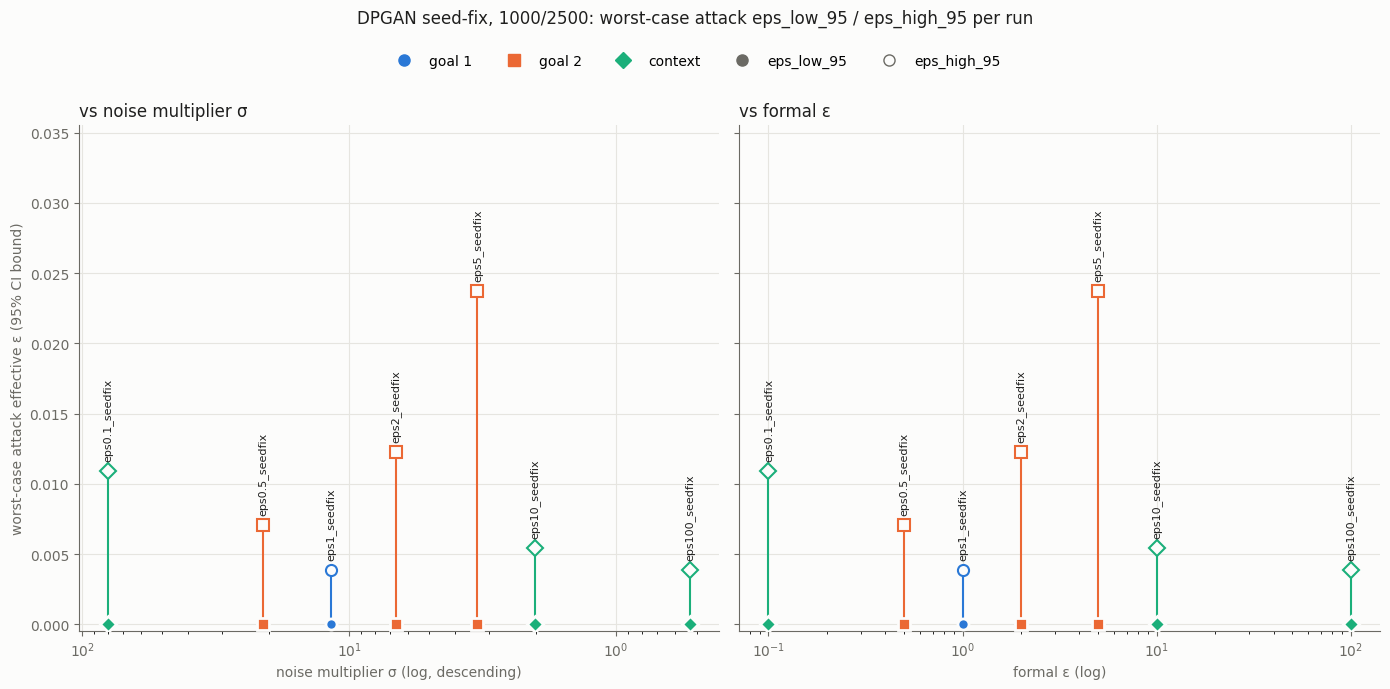

In [19]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

INK, MUTED, GRID, SURFACE, BAND = "#1f1f1e", "#6b6a64", "#e6e5e0", "#fcfcfb", "#efeee9"
GROUP_STYLE = {"goal 1": ("#2a78d6", "o"), "goal 2": ("#eb6834", "s"), "context": ("#1baf7a", "D")}

def dodge3(x, index, tol=0.02, frac=0.022):
    """Cell 13's dodge, with the row index passed in (that one reads the global W2)."""
    lx = np.log10(np.asarray(x, float))
    step = frac * (lx.max() - lx.min())
    order = np.argsort(lx, kind="stable")
    out, clusters, cluster = lx.copy(), [], [order[0]]
    def place(c):
        m = len(c)
        for i, j in enumerate(sorted(c, key=lambda j: index[j])):
            out[j] = lx[c].mean() + (i - (m - 1) / 2) * step
        if m > 1:
            clusters.append((10 ** lx[c], 10 ** out[c]))
    for j in order[1:]:
        if lx[j] - lx[cluster[-1]] < tol:
            cluster.append(j)
        else:
            place(cluster); cluster = [j]
    place(cluster)
    return 10 ** out, clusters

def band_label3(true_x, col):
    lo, hi = true_x.min(), true_x.max()
    if col == "sigma":
        val = f"σ = {lo:.7g}" if lo == hi else f"σ = {lo:.7g}–{hi:.7g}"
    else:
        val = f"ε = {lo:g}" if lo == hi else f"ε = {lo:g}–{hi:g}"
    return f"{len(true_x)} runs at {val}\n(x offset for legibility)"

fig, axes = plt.subplots(1, 2, figsize=(14, 6.4), sharey=True)
fig.patch.set_facecolor(SURFACE)
top = float(W3.eps_high_95.max())
for ax, col, xlabel in ((axes[0], "sigma", "noise multiplier σ (log, descending)"),
                        (axes[1], "epsilon", "formal ε (log)")):
    ax.set_facecolor(SURFACE)
    xs, clusters = dodge3(W3[col], W3.index)
    for true_x, plotted_x in clusters:
        pad = (plotted_x.max() / plotted_x.min()) ** (0.5 / (len(plotted_x) - 1))
        x0, x1 = plotted_x.min() / pad, plotted_x.max() * pad
        ax.axvspan(x0, x1, color=BAND, zorder=0)
        yb = top * 1.2
        ax.plot([x0, x1], [yb, yb], color=MUTED, lw=1, zorder=1, solid_capstyle="butt")
        for xe in (x0, x1):
            ax.plot([xe, xe], [yb, yb - top * 0.025], color=MUTED, lw=1, zorder=1)
        for tx in np.unique(true_x):
            ax.plot([tx, tx], [yb, yb + top * 0.035], color=INK, lw=1.5, zorder=1)
        ax.text(np.sqrt(x0 * x1), yb + top * 0.05, band_label3(true_x, col) + "\n▲ tick = true x",
                ha="center", va="bottom", fontsize=8, color=MUTED, linespacing=1.3,
                bbox=dict(boxstyle="round,pad=0.25", fc=SURFACE, ec="none"), zorder=4)
    for x, (_, w) in zip(xs, W3.iterrows()):
        color, marker = GROUP_STYLE[w.group]
        ax.plot([x, x], [w.eps_low_95, w.eps_high_95], color=color, lw=1.5, zorder=2)
        ax.plot(x, w.eps_low_95, marker=marker, ms=8, color=color, mec=SURFACE, mew=2, ls="none", zorder=3)
        ax.plot(x, w.eps_high_95, marker=marker, ms=8, mfc=SURFACE, mec=color, mew=1.5, ls="none", zorder=3)
        ax.annotate(w.run, (x, w.eps_high_95), xytext=(0, 7), textcoords="offset points",
                    rotation=90, ha="center", va="bottom", fontsize=8, color=INK)
    ax.set_xscale("log")
    if col == "sigma":
        ax.invert_xaxis()
    ax.set_xlabel(xlabel, color=MUTED)
    ax.grid(True, which="major", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(MUTED)
    ax.tick_params(colors=MUTED)
axes[0].set_ylabel("worst-case attack effective ε (95% CI bound)", color=MUTED)
axes[0].set_ylim(-0.02 * top, top * 1.5)
axes[0].set_title("vs noise multiplier σ", color=INK, loc="left")
axes[1].set_title("vs formal ε", color=INK, loc="left")

handles = [Line2D([], [], color=c, marker=m, ms=8, ls="none", label=g) for g, (c, m) in GROUP_STYLE.items()]
handles += [Line2D([], [], color=MUTED, marker="o", ms=8, ls="none", label="eps_low_95"),
            Line2D([], [], color=MUTED, marker="o", ms=8, mfc=SURFACE, ls="none", label="eps_high_95")]
fig.legend(handles=handles, loc="upper center", ncol=5, frameon=False, bbox_to_anchor=(0.5, 1.02))
fig.suptitle("DPGAN seed-fix, 1000/2500: worst-case attack eps_low_95 / eps_high_95 per run", y=1.07, color=INK)
plt.tight_layout()
plt.show()

### Cell 20: seed-fix runs next to the earlier audit at ε = 0.1 and 100
**Sources:** master table `W3` (Cell 16, all seed-fix runs) and master table `W2` (Cell 10) for the two earlier runs `eps0.1` and `eps100`, which have a seed-fix counterpart at the same ε (`eps0.1_seedfix`, `eps100_seedfix`) and so share an x position with it.
Same figure as Cells 13 and 19: left against sigma (log x, descending), right against formal ε (log x); filled marker = `eps_low_95`, hollow marker = `eps_high_95`, joined by a line. Colour and marker encode the seeding: blue circle = seed fix, green diamond = earlier audit (the two colours are Cell 13's goal 1 and context). Runs that share an x value are offset sideways for legibility (shaded band; the tick on the bracket marks the true x). Helpers (`dodge3`, `band_label3`, the colour constants) come from Cell 19.

,kind,run,epsilon,sigma,attack,tau,rule,TP/P,FP/N,eps_low_90,eps_low_95,eps_low_99,eps_high_90,eps_high_95,eps_high_99,n_tied
0,seed fix,eps0.1_seedfix,0.1000,80.0000,Groundhog,0.3100,"normal: score >= tau, label True = positive",1122/1125,1120/1125,0.0000,0.0000,0.0000,0.0098,0.0110,0.0133,5
1,earlier audit (no seed fix),eps0.1,0.1000,80.0000,Groundhog,0.5700,"normal: score >= tau, label True = positive",202/1125,179/1125,0.0000,0.0000,0.0000,0.3857,0.4231,0.4985,5
2,seed fix,eps0.5_seedfix,0.5000,20.9375,Groundhog,0.3300,"normal: score >= tau, label True = positive",1123/1125,1123/1125,0.0000,0.0000,0.0000,0.0062,0.0071,0.0089,5
3,seed fix,eps1_seedfix,1.0000,11.7188,Groundhog,0.3000,"normal: score >= tau, label True = positive",1125/1125,1125/1125,0.0000,0.0000,0.0000,0.0033,0.0039,0.0053,5
4,seed fix,eps2_seedfix,2.0000,6.6992,Groundhog,0.3600,"normal: score >= tau, label True = positive",1119/1125,1118/1125,0.0000,0.0000,0.0000,0.0109,0.0123,0.0151,5
5,seed fix,eps5_seedfix,5.0000,3.3057,Groundhog,0.3700,"normal: score >= tau, label True = positive",1102/1125,1099/1125,0.0000,0.0000,0.0000,0.0212,0.0237,0.0289,5
6,seed fix,eps10_seedfix,10.0000,2.0142,Groundhog,0.3500,"normal: score >= tau, label True = positive",1116/1125,1122/1125,0.0000,0.0000,0.0000,0.0041,0.0054,0.0081,5
7,seed fix,eps100_seedfix,100.0000,0.5273,Groundhog,0.3200,"normal: score >= tau, label True = positive",1125/1125,1125/1125,0.0000,0.0000,0.0000,0.0033,0.0039,0.0053,5
8,earlier audit (no seed fix),eps100,100.0000,0.5273,Groundhog,0.3000,"normal: score >= tau, label True = positive",1122/1125,1121/1125,0.0000,0.0000,0.0000,0.0086,0.0096,0.0118,5


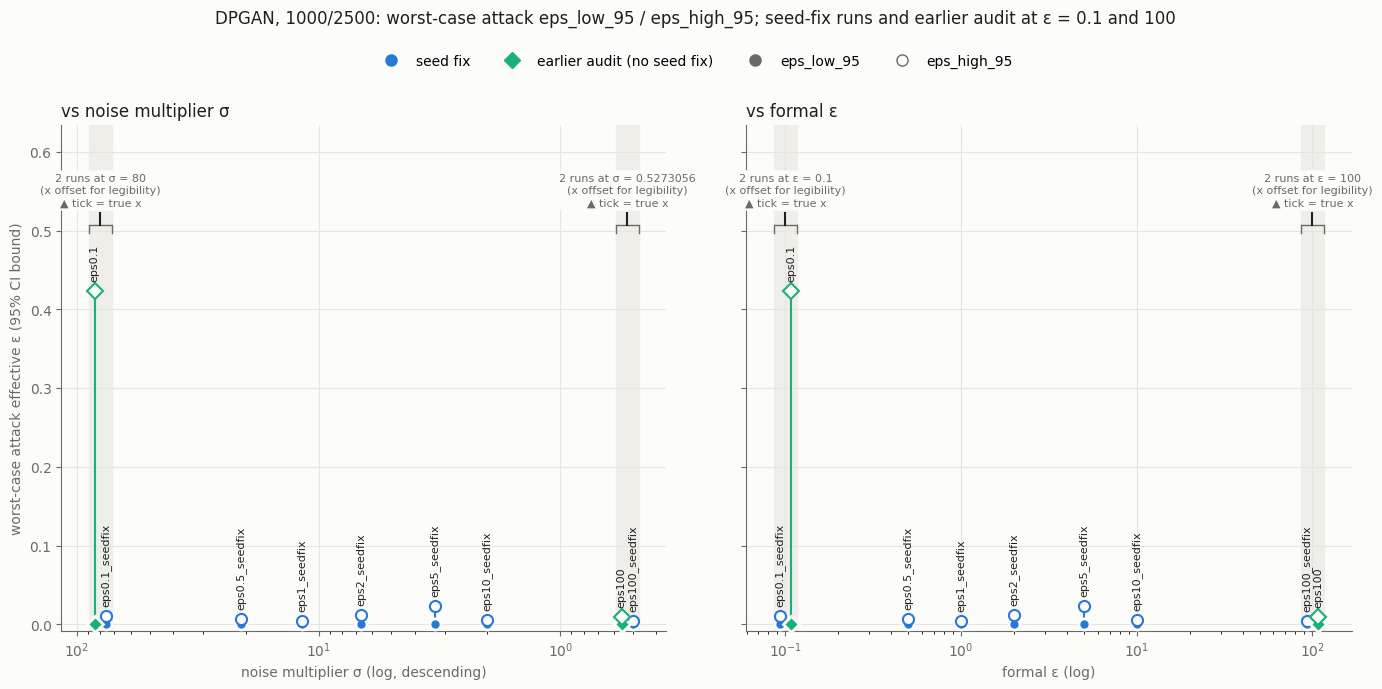

In [20]:
KIND_STYLE = {"seed fix": GROUP_STYLE["goal 1"], "earlier audit (no seed fix)": GROUP_STYLE["context"]}
W4 = (pd.concat([W3.assign(kind="seed fix"),
                 W2[W2.run.isin(["eps0.1", "eps100"])].assign(kind="earlier audit (no seed fix)")],
                ignore_index=True)
        .sort_values("sigma", ascending=False, kind="stable").reset_index(drop=True))
with pd.option_context("display.float_format", lambda x: f"{x:.4f}", "display.max_colwidth", 60):
    display(W4[["kind"] + COLS2])

fig, axes = plt.subplots(1, 2, figsize=(14, 6.4), sharey=True)
fig.patch.set_facecolor(SURFACE)
top = float(W4.eps_high_95.max())
for ax, col, xlabel in ((axes[0], "sigma", "noise multiplier σ (log, descending)"),
                        (axes[1], "epsilon", "formal ε (log)")):
    ax.set_facecolor(SURFACE)
    xs, clusters = dodge3(W4[col], W4.index)
    for true_x, plotted_x in clusters:
        pad = (plotted_x.max() / plotted_x.min()) ** (0.5 / (len(plotted_x) - 1))
        x0, x1 = plotted_x.min() / pad, plotted_x.max() * pad
        ax.axvspan(x0, x1, color=BAND, zorder=0)
        yb = top * 1.2
        ax.plot([x0, x1], [yb, yb], color=MUTED, lw=1, zorder=1, solid_capstyle="butt")
        for xe in (x0, x1):
            ax.plot([xe, xe], [yb, yb - top * 0.025], color=MUTED, lw=1, zorder=1)
        for tx in np.unique(true_x):
            ax.plot([tx, tx], [yb, yb + top * 0.035], color=INK, lw=1.5, zorder=1)
        ax.text(np.sqrt(x0 * x1), yb + top * 0.05, band_label3(true_x, col) + "\n▲ tick = true x",
                ha="center", va="bottom", fontsize=8, color=MUTED, linespacing=1.3,
                bbox=dict(boxstyle="round,pad=0.25", fc=SURFACE, ec="none"), zorder=4)
    for x, (_, w) in zip(xs, W4.iterrows()):
        color, marker = KIND_STYLE[w.kind]
        ax.plot([x, x], [w.eps_low_95, w.eps_high_95], color=color, lw=1.5, zorder=2)
        ax.plot(x, w.eps_low_95, marker=marker, ms=8, color=color, mec=SURFACE, mew=2, ls="none", zorder=3)
        ax.plot(x, w.eps_high_95, marker=marker, ms=8, mfc=SURFACE, mec=color, mew=1.5, ls="none", zorder=3)
        ax.annotate(w.run, (x, w.eps_high_95), xytext=(0, 7), textcoords="offset points",
                    rotation=90, ha="center", va="bottom", fontsize=8, color=INK)
    ax.set_xscale("log")
    if col == "sigma":
        ax.invert_xaxis()
    ax.set_xlabel(xlabel, color=MUTED)
    ax.grid(True, which="major", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color(MUTED)
    ax.tick_params(colors=MUTED)
axes[0].set_ylabel("worst-case attack effective ε (95% CI bound)", color=MUTED)
axes[0].set_ylim(-0.02 * top, top * 1.5)
axes[0].set_title("vs noise multiplier σ", color=INK, loc="left")
axes[1].set_title("vs formal ε", color=INK, loc="left")

handles = [Line2D([], [], color=c, marker=m, ms=8, ls="none", label=k) for k, (c, m) in KIND_STYLE.items()]
handles += [Line2D([], [], color=MUTED, marker="o", ms=8, ls="none", label="eps_low_95"),
            Line2D([], [], color=MUTED, marker="o", ms=8, mfc=SURFACE, ls="none", label="eps_high_95")]
fig.legend(handles=handles, loc="upper center", ncol=4, frameon=False, bbox_to_anchor=(0.5, 1.02))
fig.suptitle("DPGAN, 1000/2500: worst-case attack eps_low_95 / eps_high_95; seed-fix runs and earlier audit at ε = 0.1 and 100",
             y=1.07, color=INK)
plt.tight_layout()
plt.show()